# FDS Practical 1: Adrian Obermühlner & Daniel Schafhäutle

In [139]:
import ast
import time

import colorcet as cc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import ListedColormap
from scipy import stats
from scipy.stats import norm
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

# Set random seed for reproducibility
np.random.seed(42)

# Loading Data

In [140]:
DATA_DIR = "../../../data/"
df = pd.read_pickle(DATA_DIR + "df_train.pkl")

In [141]:
# The embeddings are stored as strings, we parse them once here
X = np.array(df["business_description_embedding"].apply(ast.literal_eval).tolist())

# Transforming Data (Label Encoding)

### Tasks:
- Use the scikit-learn label encoder to encode the industry names
- Check if all classes contained in the validation set are also in the training set

Fitting The LabelEncoder on the industry names

In [142]:
# Fit the label encoder to the classes (industry names)
label_encoder =  LabelEncoder().fit(df.industry)

Encode the labels. This encodes the industry labels with a numerical value.

In [143]:
y = label_encoder.transform(df.industry)
y

array([ 1, 15,  3, ..., 23, 21,  6], shape=(31706,))

# Visualize the data

### Tasks:
- Are certain classes over- or under represented? Either produce a table or a plot to show this.
- Inspect whether there is signal in the business description embeddings:
    - Perform a PCA to project data into 2 dimensions
    - Plot projected data in Scatterplot and color based on classes
    - Provide a description of what you see and judge whether there is signal in the data that allows industry classification

Important: Ensure that your plots have proper axis descriptions and titles. Style the plots so that differences in class distributions are visible (e.g. scatter size, transparency, color, etc.)

### Class distribution

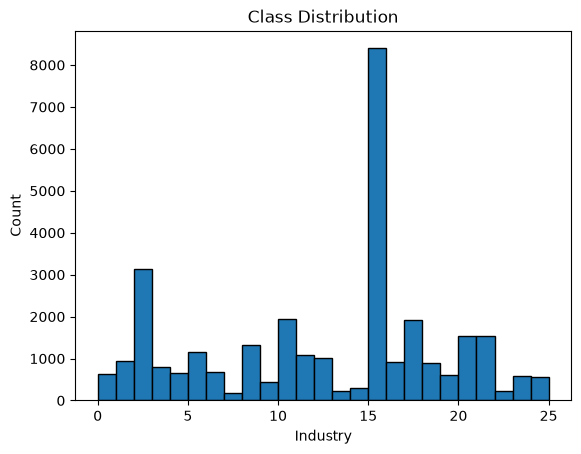

Counts per class:


industry
Materials                                         8394
Capital Goods                                     3127
Financial Services                                1936
Pharmaceuticals, Biotechnology & Life Sciences    1925
Technology Hardware & Equipment                   1547
Software & Services                               1537
Energy                                            1326
Consumer Durables & Apparel                       1164
Food, Beverage & Tobacco                          1094
Health Care Equipment & Services                  1014
Banks                                              948
Media & Entertainment                              915
Real Estate Management & Development               906
Commercial & Professional Services                 804
Consumer Services                                  672
Consumer Discretionary Distribution & Retail       658
Automobiles & Components                           625
Semiconductors & Semiconductor Equipment           607
T

In [144]:
# Plot the class distribution or provide a table that shows how many times each class (industry) appears
# Describe your findings
n_industries = len(np.unique(y))
plt.hist(y, bins=np.arange(n_industries + 1), edgecolor="black")
plt.title("Class Distribution")
plt.xlabel("Industry")
plt.ylabel("Count")
plt.show()

print("Counts per class:")
df.industry.value_counts()

There are some industries like "materials" and "capital goods" that contain a lot more samples than others. Then there is a large middle section of industries with 500 to 1000  samples and at the end is a small number of industries who have fewer than 500 samples.

Because a quarter of the samples in the raw data is of the industry "materials", a naive classifier that only predicts that class can already reach an accuracy of ca. ~25%. 

To make sure that the classifier learns to predict the right class and not only that this is the majority class, we need to account for this.

This could be done through adjusting the loss function or using a classifier that can inversely weight the samples by the class's frequency.

A different approach would be to use a technique like SMOTE, or reducing the number of samples in the majority class to make it more equal. Although i think that we do want to use all the samples that we have.

Regarding if these numbers make sense. I am not 100% sure, but I think they look mostly sensible. Though since there appears to be some overlap between industries the classification could change depending on what the company views itself as, this nuance could be hard for our classifier to detect.

### PCA - Dimensionality reduction and visualization

Projected data from (31706, 768) to (31706, 2)


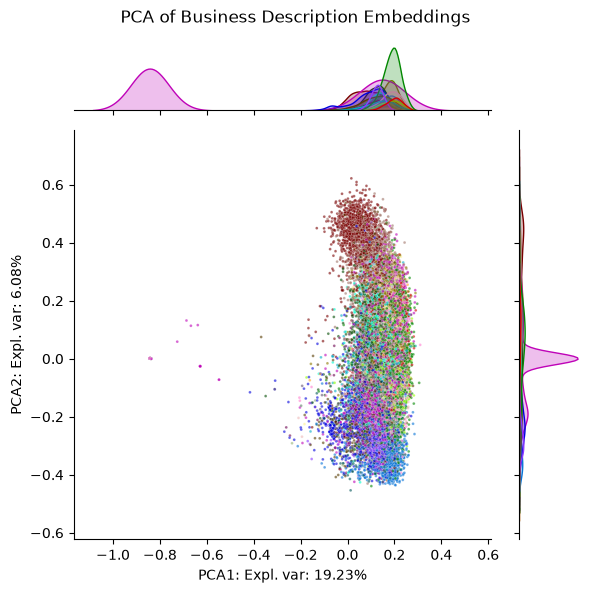

In [145]:
# Perform a PCA and plot the projected data. Color the scatter plot based on the classes
# Analyse what you see

# PCA 
pca_decomp = PCA(n_components=2).fit(X)
pca = pca_decomp.transform(X)
print(f"Projected data from {X.shape} to {pca.shape}")

# Create colormap with as many colors as there are industries
n_industries = len(np.unique(y))
industry_cmap = ListedColormap(cc.glasbey[:n_industries])

# Plot the first two principal components
g = sns.jointplot(x=pca[:, 0], y=pca[:, 1], hue=y, palette=industry_cmap, s= 4, alpha=0.6, legend=False)
#set title
g.figure.suptitle("PCA of Business Description Embeddings")
g.figure.tight_layout()
g.set_axis_labels(f"PCA1: Expl. var: {pca_decomp.explained_variance_ratio_[0] * 100:.2f}%", f"PCA2: Expl. var: {pca_decomp.explained_variance_ratio_[1] * 100:.2f}%")
plt.show()


It looks like there are potential outliers in the dataset or something else that distorts the result, since there are almost no points on the left side of the plot. But something needs to be there if PCA decided that that direction is most valuable to keep. 

Otherwise the data looks to be somewhat separable, although there is some overlap between classes and some are more clearly defined than others.

We will try to investigate this result further and find the reason for this distorted plot. 

A significant part of the distributions is centered on these outliers. But there is a second peak in PCA1 where all the other points also are. It seems like a few points there are distorting everything. These points are part of a larger group though.

It is suspected that there are a lot of very similar or even duplicate samples on the left side since if there were really only these ~10 points in that area, that would not be enough to distort the plot like this. 

To investigate this we look at the embeddings of the business descriptions, duplicates and other dimensions of the pca to see if the other dimensions look better

In [146]:
def plot_explore_pca(X_data, y_data, first_n_components = 5, title = "PCA of Business Description Embeddings in multiple pca dimensions"):
    # Get PCA of the reduced dataset
    pca_decomp = PCA(n_components=first_n_components).fit(X_data)
    pca = pca_decomp.transform(X_data)

    fig, axes = plt.subplots(first_n_components, first_n_components, figsize=(16, 16))
    plt.suptitle(title)

    for i in range(first_n_components):
        for j in range(first_n_components):
            if i == j:
                axes[i, j].set_xticks([])
                axes[i, j].set_yticks([])   
                continue

            sns.scatterplot(x=pca[:, i], y=pca[:, j], hue=y_data, palette=industry_cmap, s= 4, alpha= 0.6, ax=axes[i, j], legend=False)
            axes[i, j].set_xlabel(f"PCA{i+1}: Expl. var: {pca_decomp.explained_variance_ratio_[i] * 100:.2f}%")
            axes[i, j].set_ylabel(f"PCA{j+1}: Expl. var: {pca_decomp.explained_variance_ratio_[j] * 100:.2f}%")
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])  
 
    plt.tight_layout()
    plt.show()

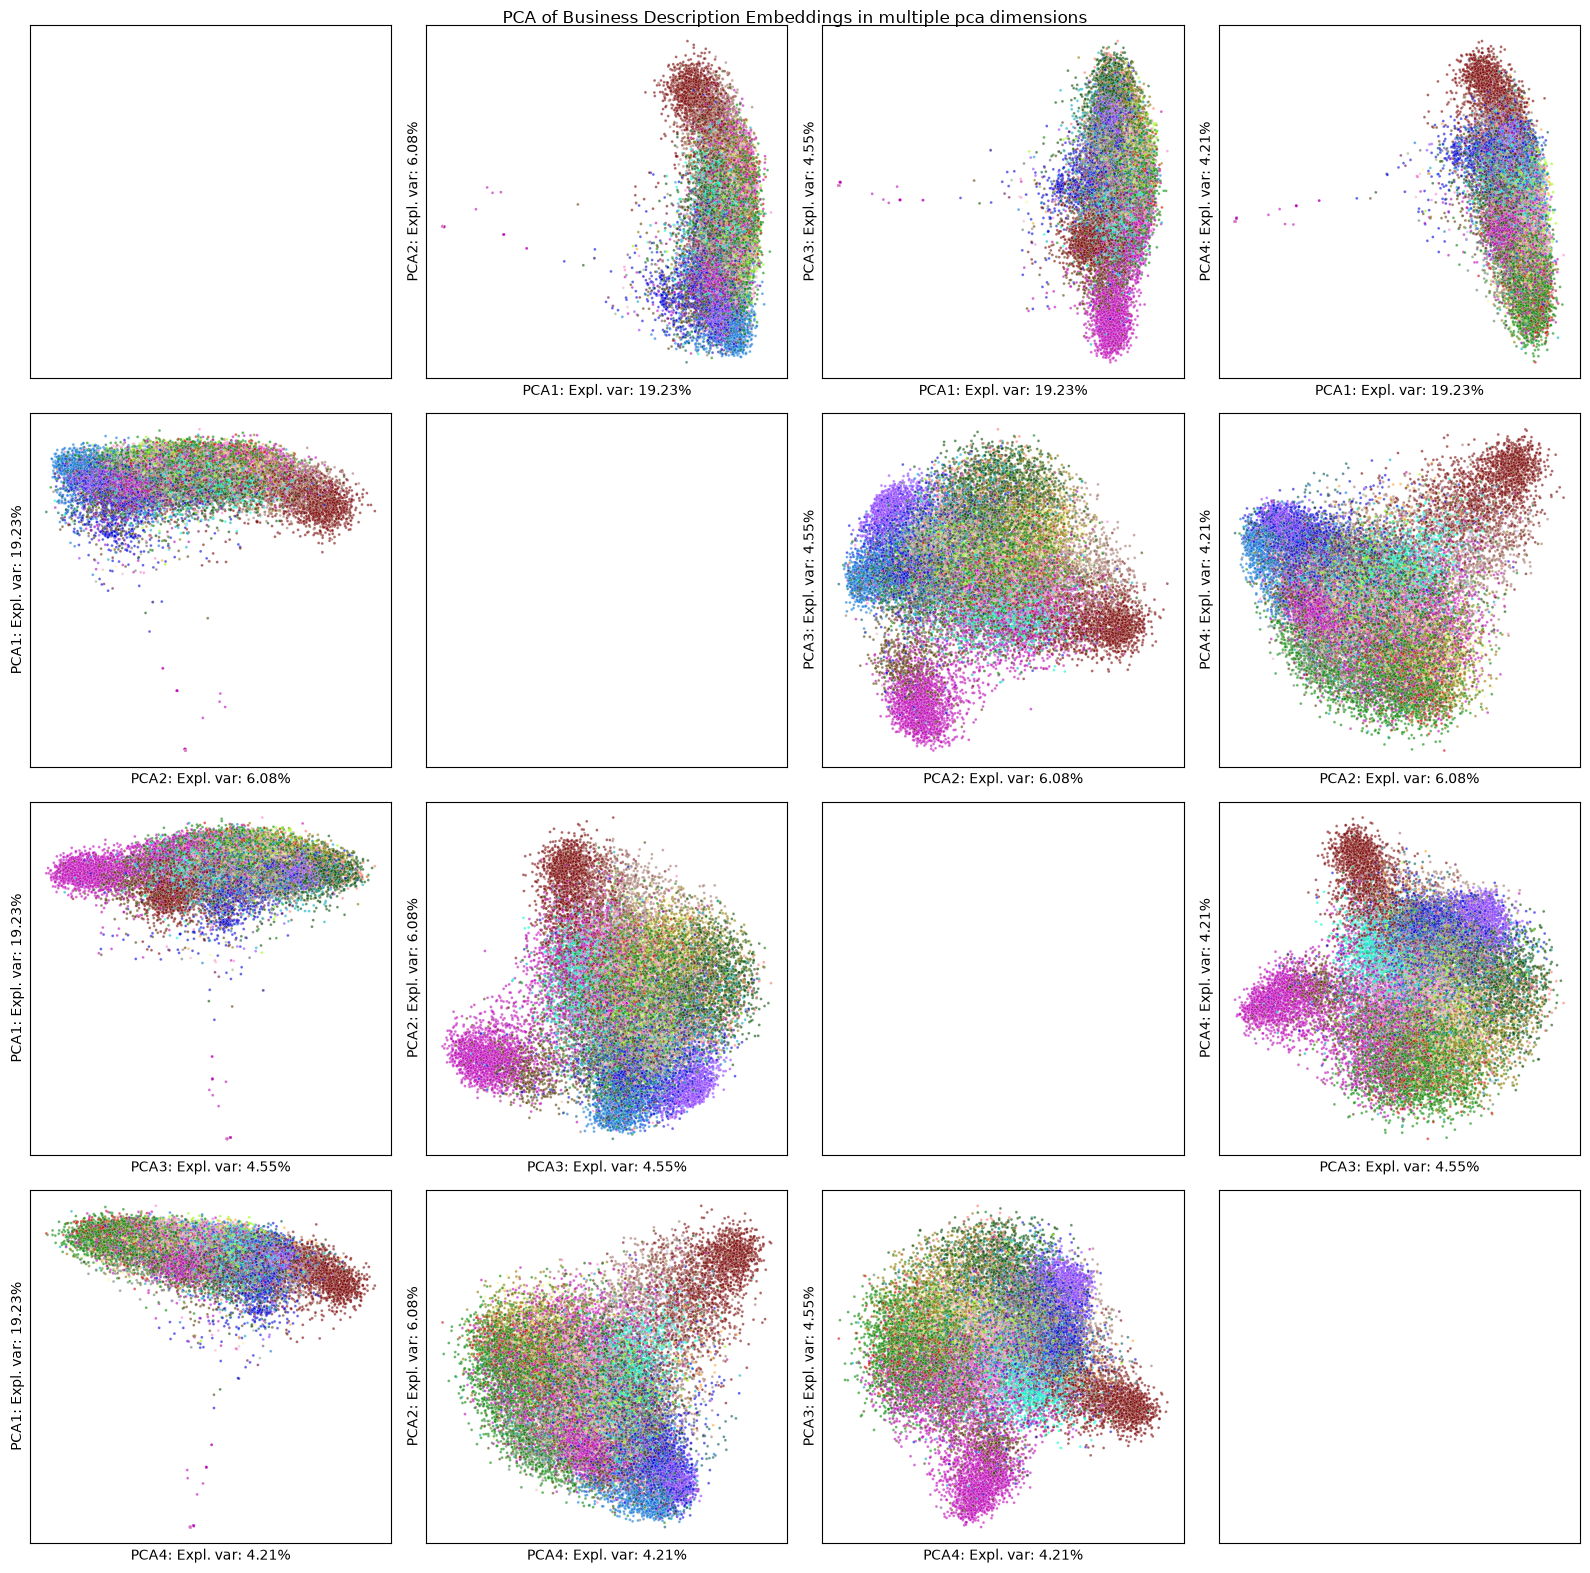

In [147]:
plot_explore_pca(X, y, first_n_components=4)

Plots containing PCA 1 are distorted by some outliers. The other components look fine

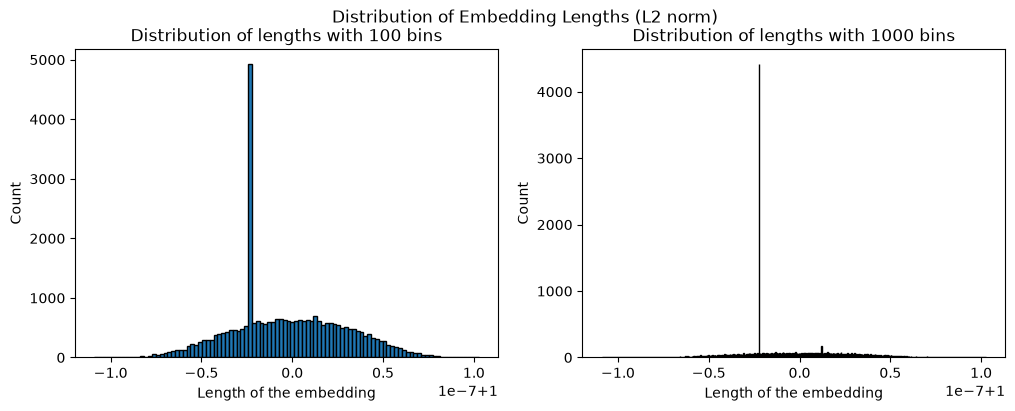

Min length:  0.9999998910388799
Max length:  1.0000001026570713


In [148]:
# Distribution of the length || x_i ||² of the business description embeddings
# If there are a lot of duplicates or near duplicates we should be able to observe that
# The plots show "negative" because it is in scientific notation. 1e-7+1 shifts it to the right.
def plot_embedding_length_distribution(embeddings: np.ndarray, title = "Distribution of Embedding Lengths (L2 norm)"):

    l2_lengths = np.linalg.norm(embeddings, axis=1, ord=2)


    plt.figure(figsize=(12, 4))
    plt.suptitle(title)

    plt.subplot(1, 2, 1)
    plt.title("Distribution of lengths with 100 bins")
    plt.hist(l2_lengths, bins=100, edgecolor="black")
    plt.xlabel("Length of the embedding")
    plt.ylabel("Count")

    plt.subplot(1, 2, 2)
    plt.title("Distribution of lengths with 1000 bins")
    plt.hist(l2_lengths, bins=1000, edgecolor="black")
    plt.xlabel("Length of the embedding")
    plt.ylabel("Count")
    
    plt.show()

    print("Min length: ", np.min(l2_lengths))
    print("Max length: ", np.max(l2_lengths))

plot_embedding_length_distribution(X)

There are a lot of duplicates or near-duplicates in the data. There is one high spike of approximately 4000 samples that are very close together (or are just the same distance from the origin).

Since they are exact duplicates, this is likely an error in the data and we should remove them. They wont give the model a good learning signal. 

We'll look at the distribution of Embedding Lengths and the PCAs again to see if it looks better.

Number of exact duplicate embeddings: 4578
industry
Materials                                         0.144390
Capital Goods                                     0.115195
Pharmaceuticals, Biotechnology & Life Sciences    0.070849
Name: proportion, dtype: float64


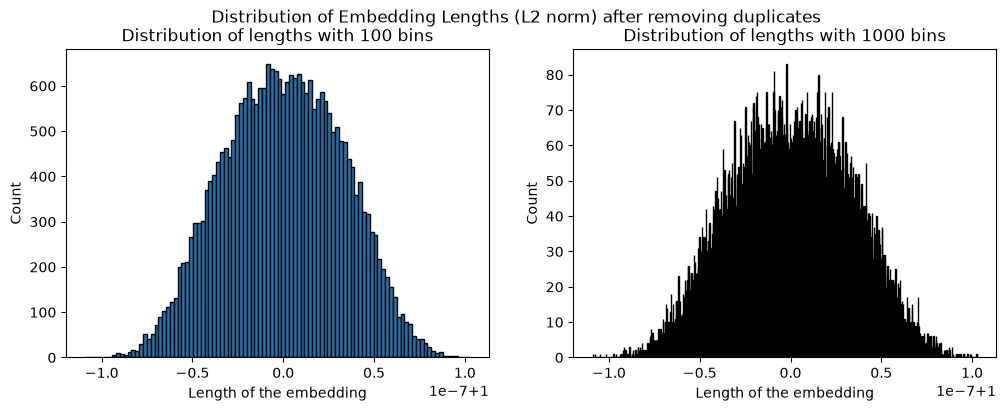

Min length:  0.9999998910388799
Max length:  1.0000001026570713


In [149]:
def remove_duplicates(df, X, y):
    is_duplicate = df["business_description_embedding"].duplicated().to_numpy()
    print(f"Number of exact duplicate embeddings: {is_duplicate.sum()}")
    return df[~is_duplicate].reset_index(drop=True), X[~is_duplicate], y[~is_duplicate]


df, X, y = remove_duplicates(df, X, y)
print(df.industry.value_counts(normalize=True).head(3))

plot_embedding_length_distribution(X, title="Distribution of Embedding Lengths (L2 norm) after removing duplicates")

Almost all of the big duplicate group is Materials. After removing the duplicates Materials drops from 26.5% to 14.4% of the data, so a naive classifier would now only reach about 14%.

There are no more visible outliers

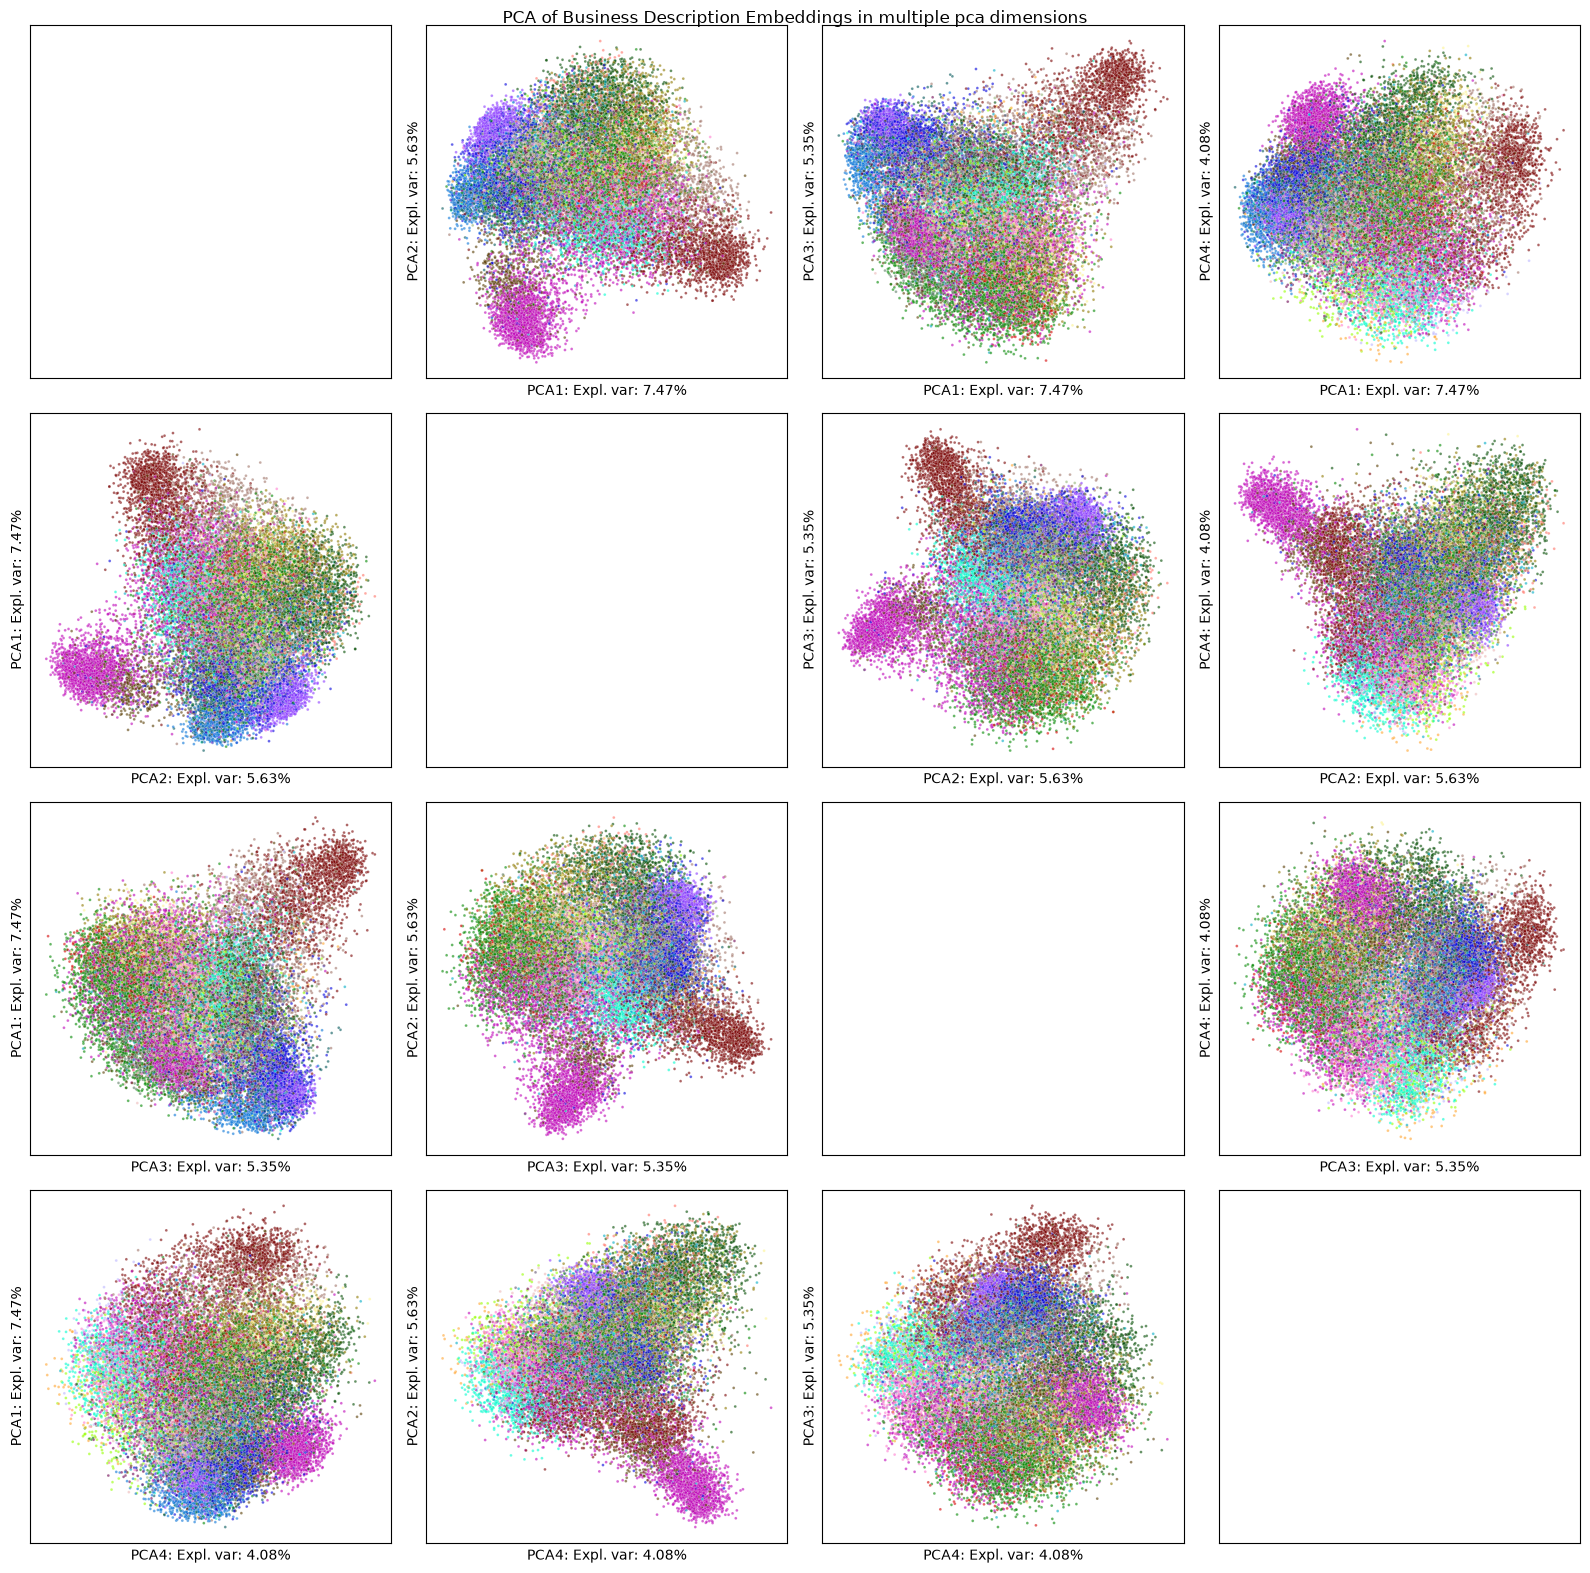

In [150]:
plot_explore_pca(X, y, first_n_components=4)

PCA plots also look way better and are not distorted anymore

# Fitting and comparing Classifier Models

### Tasks:
- Split the data into train and validation data
- Encode the industry labels using LabelEncoder (scikit-learn)
- Fit a LogisticRegression and a kNN-classifier
- Compare the model performance of both models:
    - Compute Accuracy and F1 score
        - Interpret the scores: Explain how they are computed and judge if your model performs well
        - Analyze the classification errors: 
            - Do the errors correlate with how well classes are represented?
            - Which industries does the model identify well and which seem to be similar?
    - Plot a confusion matrix for both models (combine scikit-learn confusion matrix and seaborn heatmap plot)
    - Do both models misclassify the same examples?

Import: Use proper axis labels for the plots! 

We split the data into train and validation set after removing the duplicates, so the same company can't end up on both sides. Then we fit LogisticRegression and kNN.

Check if the classes contained in the validation set are also in the training set. This is important, since a model wont be able to predict for unseen classes. 

In [151]:
train_idx, val_idx = train_test_split(np.arange(len(y)), test_size=0.1, random_state=42, stratify=y)
X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]

print(f"Train: {len(y_train)} Val: {len(y_val)}")
print(f"Train count {len(np.unique(y_train))} Val count {len(np.unique(y_val))}")
if set(y_val) <= set(y_train):
    print("All val labels are also in train set")
else:
    print("Val contains labels that are NOT in the train set")

Train: 24415 Val: 2713
Train count 25 Val count 25
All val labels are also in train set


#### Evaluation


In [152]:
def score_model(y_true, y_pred, print_results=True): 
    # Accuracy 
    accuracy =  accuracy_score(y_true, y_pred)
    # F1 score 
    f1_macro = f1_score(y_true, y_pred, average="macro")
    f1_micro = f1_score(y_true, y_pred, average="micro") 
    f1_weighted = f1_score(y_true, y_pred, average="weighted")
    
    scores = {
        "accuracy": accuracy,
        "f1_macro": f1_macro,
        "f1_micro": f1_micro,
        "f1_weighted": f1_weighted
    } 
    
    if print_results:
        print(f"Accuracy: {accuracy:.4f}")
        print(f"F1 macro: {f1_macro:.4f}")
        print(f"F1 micro: {f1_micro:.4f}")
        print(f"F1 weighted: {f1_weighted:.4f}")


    return scores 


**F1 Score (Binary)**
Harmonic mean of precision and recall. The model needs to achieve good precision and recall to receive a good F1 score, maximising one of them is not enough. It provides a good compromise when both are equally important. 
$$
F1_{binary} = \frac{2*TP}{2*TP+FP+FN}
$$

**F1 Score (Micro)**

F1 is usually a binary metric. It is extended to multiclass classification by performing some sort of aggregation or averaging. 
For the Micro F1. The total nr of true positives, false negatives and false positives are counted across all predictions.

Then the F1 Metric is calculated using these aggregated TP/FP/FN counts with the above formula.

**F1 Score (Macro)**

Calculate the F1 for each label separately. 
Get TP/FP/FN for each label, calculate its binary F1, then take the _unweighted_ average.
Does not take label imbalance into account. Every class is equally important.


**F1 Score (Weighted)**

Same as macro F1, but here the average is weighted by the support, which is the nr of true instances for each label (as seen in the ground truth labels y_true). Classes with higher support have more weight.

#### LogisticRegression

In [153]:
# Logistic Regression with default parameters
log_reg = LogisticRegression(max_iter=200).fit(X_train, y_train)
probs_log_reg = log_reg.predict_proba(X_val) #(n_samples, k_classes)
y_pred_log_reg = log_reg.classes_[np.argmax(probs_log_reg, axis=1)] #(n_samples,)
confidence_log_reg = np.max(probs_log_reg, axis=-1) #(n_samples,)

log_reg_scores = score_model(y_val, y_pred_log_reg)

Accuracy: 0.7376
F1 macro: 0.7056
F1 micro: 0.7376
F1 weighted: 0.7326


#### K-NN Classifier

Getting the best _n\_neighbors_ value using the Elbow method

In [154]:
def elbow_method_knn(X_train, y_train, X_val, y_val, plot=True):

    results = {
        "f1_macro": [],
        "f1_micro": [],
        "f1_weighted": [],
        "accuracy": []
    }
    k_values = list(range(1,30,2))
    for k in k_values:
        knn_classifier = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
        probs = knn_classifier.predict_proba(X_val)
        y_pred = knn_classifier.classes_[np.argmax(probs, axis=1)]
        confidence = np.max(probs, axis=-1)
        
        scores = score_model(y_val, y_pred, print_results=False)
        print(
            f"k: {k} accuracy: {scores['accuracy']:.4f} "
            f"f1_macro: {scores['f1_macro']:.4f} "
            f"f1_micro: {scores['f1_micro']:.4f} "
            f"f1_weighted: {scores['f1_weighted']:.4f}"
        )
        results["f1_macro"].append(scores["f1_macro"])
        results["f1_micro"].append(scores["f1_micro"])
        results["f1_weighted"].append(scores["f1_weighted"])
        results["accuracy"].append(scores["accuracy"])
        

    # best k for each metric 
    for key, value in results.items(): 
        print(f"Best k for {key}: {k_values[np.argmax(value)]}")


    if plot:
        # plot all metrics
        plt.figure(figsize=(10, 5))
        plt.plot(k_values, results["f1_macro"], label="F1 Macro")
        plt.plot(k_values, results["f1_micro"], label="F1 Micro")
        plt.plot(k_values, results["f1_weighted"], label="F1 Weighted")
        plt.plot(k_values, results["accuracy"], label="Accuracy")
        plt.title("Elbow method for KNN classifier")
        plt.xlabel("k")
        plt.ylabel("Score")
        plt.legend()
        plt.show()

k: 1 accuracy: 0.6668 f1_macro: 0.6424 f1_micro: 0.6668 f1_weighted: 0.6656
k: 3 accuracy: 0.6974 f1_macro: 0.6723 f1_micro: 0.6974 f1_weighted: 0.6959
k: 5 accuracy: 0.7239 f1_macro: 0.6956 f1_micro: 0.7239 f1_weighted: 0.7198
k: 7 accuracy: 0.7372 f1_macro: 0.7044 f1_micro: 0.7372 f1_weighted: 0.7327
k: 9 accuracy: 0.7449 f1_macro: 0.7182 f1_micro: 0.7449 f1_weighted: 0.7403
k: 11 accuracy: 0.7405 f1_macro: 0.7137 f1_micro: 0.7405 f1_weighted: 0.7358
k: 13 accuracy: 0.7453 f1_macro: 0.7174 f1_micro: 0.7453 f1_weighted: 0.7407
k: 15 accuracy: 0.7464 f1_macro: 0.7158 f1_micro: 0.7464 f1_weighted: 0.7419
k: 17 accuracy: 0.7427 f1_macro: 0.7122 f1_micro: 0.7427 f1_weighted: 0.7375
k: 19 accuracy: 0.7460 f1_macro: 0.7124 f1_micro: 0.7460 f1_weighted: 0.7408
k: 21 accuracy: 0.7460 f1_macro: 0.7150 f1_micro: 0.7460 f1_weighted: 0.7405
k: 23 accuracy: 0.7449 f1_macro: 0.7072 f1_micro: 0.7449 f1_weighted: 0.7394
k: 25 accuracy: 0.7405 f1_macro: 0.7055 f1_micro: 0.7405 f1_weighted: 0.7345
k: 2

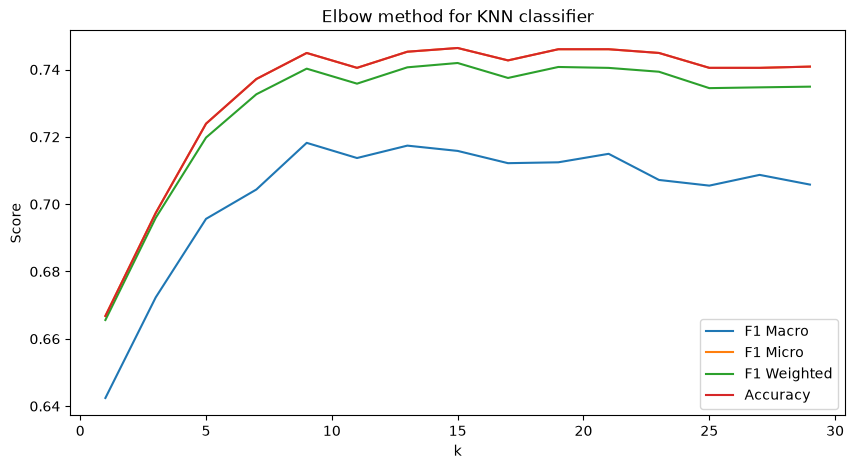

In [155]:
elbow_method_knn(X_train, y_train, X_val, y_val, plot=True)

k=19 looks like the sweet spot, though, macro f1 has a slightly higher peak at k=11.

Actually we can see here that in multi class classification, micro F1 is identical to accuracy. This does not hold for multi-label classification though. 

Now we fit a KNN with n neighbors = 19

In [156]:
knn_classifier = KNeighborsClassifier(n_neighbors=19).fit(X_train, y_train) # get n with elbow method
probs_knn = knn_classifier.predict_proba(X_val)
y_pred_knn = knn_classifier.classes_[np.argmax(probs_knn, axis=1)]
confidence_knn = np.max(probs_knn, axis=-1)

knn_scores = score_model(y_val, y_pred_knn)

Accuracy: 0.7460
F1 macro: 0.7124
F1 micro: 0.7460
F1 weighted: 0.7408


In [157]:
# compare knn and logistic regression model 
def add_model_scores(df, model_scores, model_name): 
    model_scores.update({"model": model_name})
    df.loc[len(df)] = model_scores

df_model_comparison = pd.DataFrame(columns=["model", "accuracy", "f1_macro", "f1_micro", "f1_weighted"])

add_model_scores(df_model_comparison, log_reg_scores, "logistic regression")
add_model_scores(df_model_comparison, knn_scores, "k-nn")

df_model_comparison

,model,accuracy,f1_macro,f1_micro,f1_weighted
0,logistic regression,0.737560,0.705611,0.737560,0.732649
1,k-nn,0.746038,0.712442,0.746038,0.740766


From these aggregated metrics it looks like both models performances are very similar to each others. Logistic regression has slightly higher scores in all metrics.

However, the aggregated F1s might hide some differences, lets look at the binary f1 scores

In [158]:
f1_scores_knn_per_class = f1_score(y_val, y_pred_knn, average=None)
f1_scores_log_reg_per_class = f1_score(y_val, y_pred_log_reg, average=None)

support_list = [(y_val == i).sum() / len(y_val) for i in range(n_industries)]


print("F1 scores per class:")
for i in range(len(f1_scores_knn_per_class)):
    support = (y_val == i).sum() / len(y_val)
    support_train = (y_train == i).sum() / len(y_train)
    print(f"Class {i:2d}: KNN: {f1_scores_knn_per_class[i]:.4f} LogReg: {f1_scores_log_reg_per_class[i]:.4f} Support val: {support*100:.2f}% Support train: {support_train*100:.2f}%")


F1 scores per class:
Class  0: KNN: 0.8000 LogReg: 0.7874 Support val: 2.29% Support train: 2.31%
Class  1: KNN: 0.8824 LogReg: 0.9368 Support val: 3.50% Support train: 3.49%
Class  2: KNN: 0.7143 LogReg: 0.6880 Support val: 11.54% Support train: 11.52%
Class  3: KNN: 0.4425 LogReg: 0.4706 Support val: 2.95% Support train: 2.95%
Class  4: KNN: 0.5238 LogReg: 0.4956 Support val: 2.43% Support train: 2.42%
Class  5: KNN: 0.7222 LogReg: 0.7080 Support val: 4.28% Support train: 4.29%
Class  6: KNN: 0.7812 LogReg: 0.8154 Support val: 2.47% Support train: 2.48%
Class  7: KNN: 0.5806 LogReg: 0.5185 Support val: 0.66% Support train: 0.66%
Class  8: KNN: 0.6525 LogReg: 0.6525 Support val: 4.87% Support train: 4.85%
Class  9: KNN: 0.7733 LogReg: 0.8046 Support val: 1.55% Support train: 1.56%
Class 10: KNN: 0.7500 LogReg: 0.7661 Support val: 6.93% Support train: 6.95%
Class 11: KNN: 0.8596 LogReg: 0.8340 Support val: 4.02% Support train: 4.03%
Class 12: KNN: 0.7867 LogReg: 0.7745 Support val: 3.7

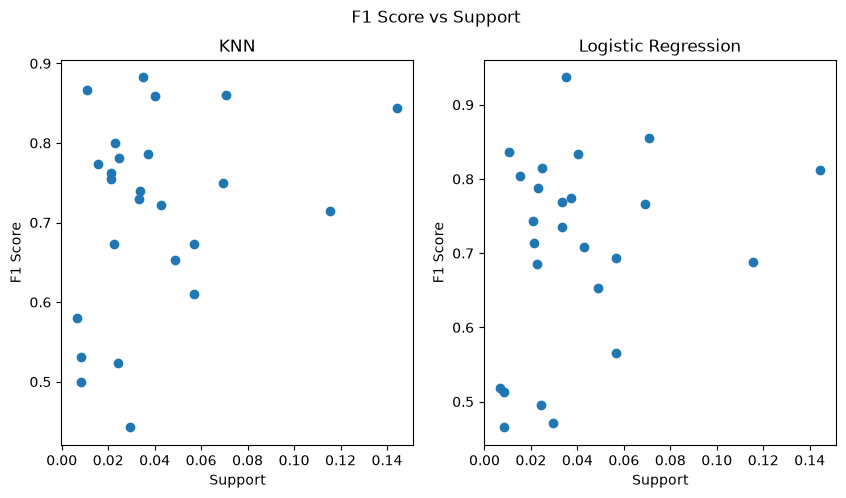

In [159]:
# plot class support vs f1 score
plt.figure(figsize=(10, 5))
plt.subplot(1,2,1)
plt.title("KNN")
plt.scatter(support_list, f1_scores_knn_per_class, label="F1 KNN")
plt.xlabel("Support")
plt.ylabel("F1 Score")
plt.subplot(1,2,2)
plt.title("Logistic Regression")
plt.scatter(support_list, f1_scores_log_reg_per_class, label="F1 LogReg")
plt.xlabel("Support")
plt.ylabel("F1 Score")
plt.suptitle("F1 Score vs Support")
plt.show()


There does not seem to be a clear correlation between the support of a class and the models f1 score for that class.

In [160]:
corr_support_f1_knn = np.corrcoef(support_list, f1_scores_knn_per_class)
corr_support_f1_log_reg = np.corrcoef(support_list, f1_scores_log_reg_per_class)

print(f"Correlation support F1 KNN: {corr_support_f1_knn[0,1]:.4f}")
print(f"Correlation support F1 Logistic Regression: {corr_support_f1_log_reg[0,1]:.4f}")


Correlation support F1 KNN: 0.2937
Correlation support F1 Logistic Regression: 0.2617


Correlation between nr of samples in a class and the models f1 score on that class is weak for both models $r<0.2$.

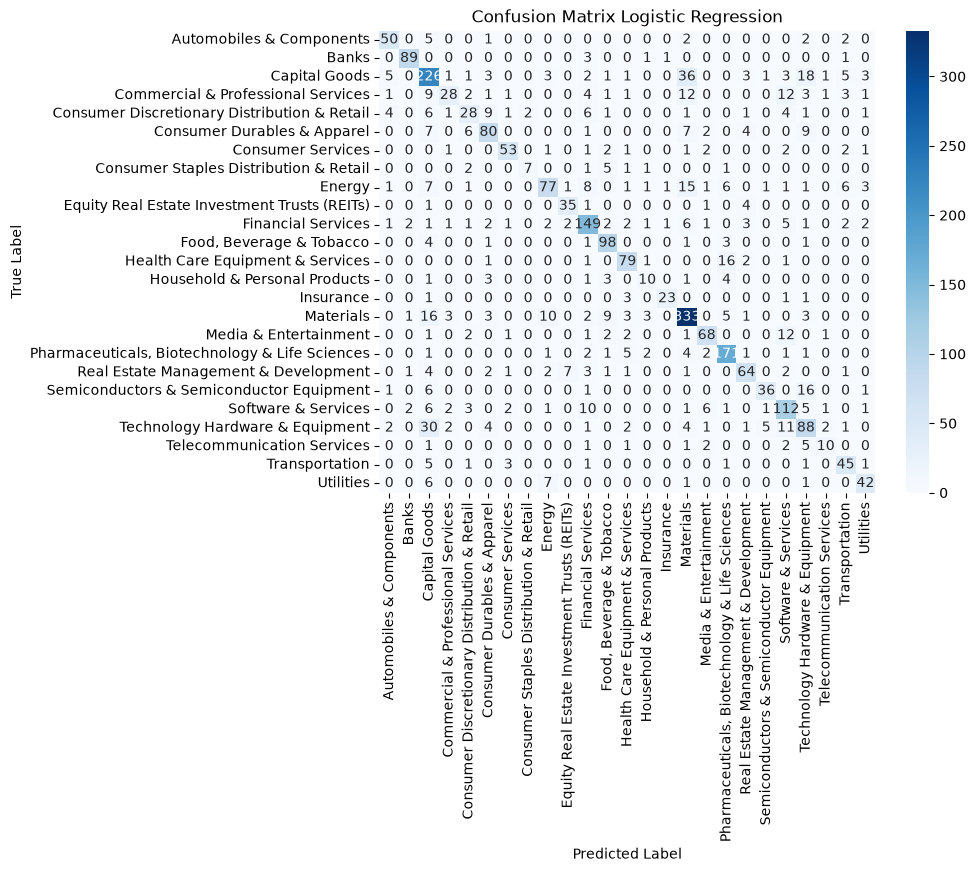

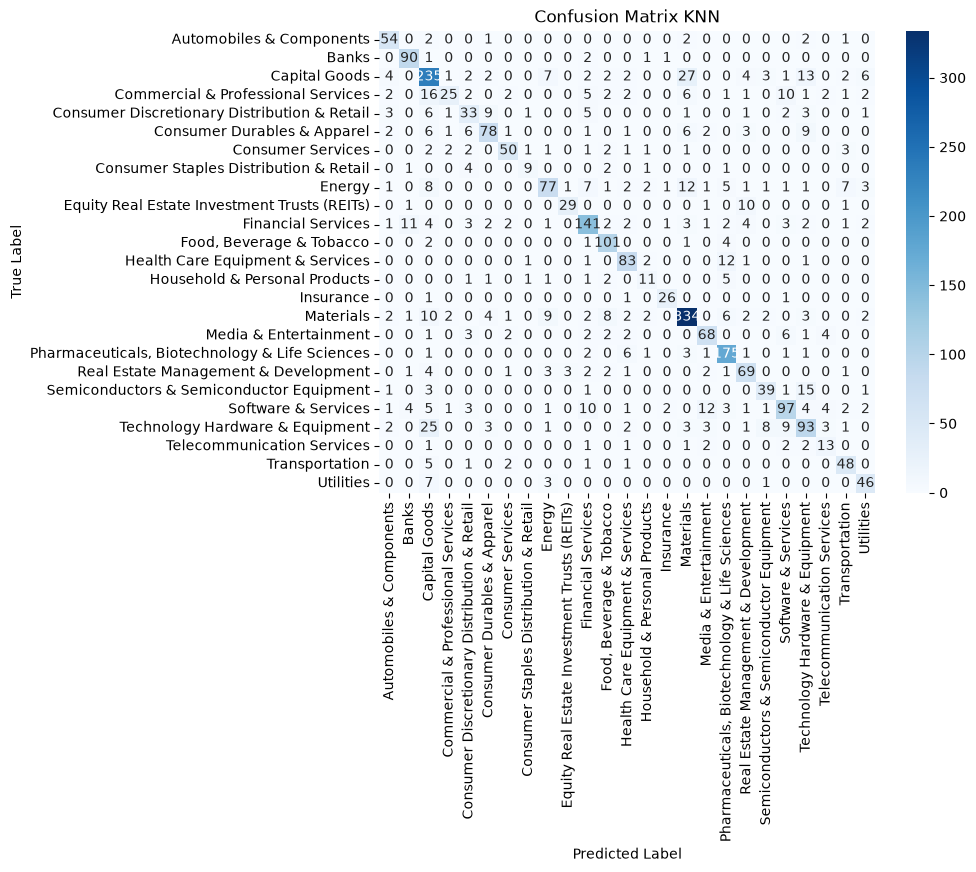

In [161]:
# i would like to plot the confusion matrices
conf_matrix_knn = confusion_matrix(y_val, y_pred_knn)
conf_matrix_log_reg = confusion_matrix(y_val, y_pred_log_reg)

# plot confusion matrix
plt.figure(figsize=(8, 6))
plt.title("Logistic Regression")
sns.heatmap(
    conf_matrix_log_reg,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.inverse_transform(log_reg.classes_),
    yticklabels=label_encoder.inverse_transform(log_reg.classes_)
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix Logistic Regression")
plt.show()


plt.figure(figsize=(8, 6))
plt.title("KNN")
sns.heatmap(
    conf_matrix_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.inverse_transform(knn_classifier.classes_),
    yticklabels=label_encoder.inverse_transform(knn_classifier.classes_)
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix KNN")
plt.show()

In [162]:
def get_top_misclassifications_by_percentage(conf_matrix, class_names, top_n=5):
    """
    Find the top_n most frequent misclassifications by percentage (off-diagonal).
    Returns a DataFrame with the true class, predicted class, count, and percentage of misclassification for that true class.
    """
    miscls = []
    for i, true_class in enumerate(class_names):
        row = conf_matrix[i].copy()
        n_total = row.sum()
        row[i] = 0  # ignore correct predictions
        for j, count in enumerate(row):
            if count > 0:
                percent = count / n_total if n_total > 0 else 0
                miscls.append({
                    "True Class": true_class,
                    "Predicted as": class_names[j],
                    "Count": count,
                    "Percent": percent
                })
    df = pd.DataFrame(miscls)
    if not df.empty:
        df = df.sort_values(by="Percent", ascending=False).head(top_n)
    return df

class_names_knn = label_encoder.inverse_transform(knn_classifier.classes_)
class_names_log_reg = label_encoder.inverse_transform(log_reg.classes_)
top_n = 8

print(f"\nTop {top_n} Misclassifications by Percentage in Logistic Regression Classifier:")
top_misc_log = get_top_misclassifications_by_percentage(conf_matrix_log_reg, class_names_log_reg, top_n=top_n)
display(top_misc_log)


print(f"Top {top_n} Misclassifications by Percentage in KNN Classifier:")
top_misc_knn = get_top_misclassifications_by_percentage(conf_matrix_knn, class_names_knn, top_n=top_n)
display(top_misc_knn)




Top 8 Misclassifications by Percentage in Logistic Regression Classifier:


,True Class,Predicted as,Count,Percent
71,Consumer Staples Distribution & Retail,"Food, Beverage & Tobacco",5,0.277778
184,Semiconductors & Semiconductor Equipment,Technology Hardware & Equipment,16,0.262295
219,Telecommunication Services,Technology Hardware & Equipment,5,0.217391
201,Technology Hardware & Equipment,Capital Goods,30,0.194805
132,Household & Personal Products,"Pharmaceuticals, Biotechnology & Life Sciences",4,0.173913
124,Health Care Equipment & Services,"Pharmaceuticals, Biotechnology & Life Sciences",16,0.158416
33,Commercial & Professional Services,Materials,12,0.150000
34,Commercial & Professional Services,Software & Services,12,0.150000


Top 8 Misclassifications by Percentage in KNN Classifier:


,True Class,Predicted as,Count,Percent
185,Semiconductors & Semiconductor Equipment,Technology Hardware & Equipment,15,0.245902
96,Equity Real Estate Investment Trusts (REITs),Real Estate Management & Development,10,0.238095
73,Consumer Staples Distribution & Retail,Consumer Discretionary Distribution & Retail,4,0.222222
132,Household & Personal Products,"Pharmaceuticals, Biotechnology & Life Sciences",5,0.217391
25,Commercial & Professional Services,Capital Goods,16,0.200000
205,Technology Hardware & Equipment,Capital Goods,25,0.162338
42,Consumer Discretionary Distribution & Retail,Consumer Durables & Apparel,9,0.136364
34,Commercial & Professional Services,Software & Services,10,0.125000


In [163]:
wrong_log_reg = y_pred_log_reg != y_val
wrong_knn = y_pred_knn != y_val
print(f"Wrong in logistic regression: {wrong_log_reg.sum()}")
print(f"Wrong in KNN: {wrong_knn.sum()}")
print(f"Wrong in both: {(wrong_log_reg & wrong_knn).sum()}")

Wrong in logistic regression: 712
Wrong in KNN: 689
Wrong in both: 547


There are a few classes that the model has problems classifying correctly.

There is a lot of confusion for the classes: Consumer Staples Distribution & Retail, Commercial & Professional Services, Semiconductor & Semiconductor Equipment, Technology Hardware & Equipment.

Most of the misclassifications seem between classes that are pretty similar to each other.  

Both models make the same errors. E.g. both misclassify a lot of Commercial & Professional Services with Capital Goods.

# Optional: Confidence Weighted Prediction

## Deliverables:

- Provide a notebook with the implementation and training of an industry classifier model
- The model shall output the industry classification and its confidence as a tuple of vectors $(\hat{y}_{pred}, \hat{y}_{confidence})$
- The confidence score must be between 0 and 1, $\hat{y}_{confidence} [i] \in [0,1]$
- Your model will be evaluated on a private test set
- Designing the confidence score is your task. You may use p-values, a voting mechanism of multiple models, or other techniques
- Another option is to add more features, e.g. financial data, to X

## Scoring

Your submission is scored with the function `confidence_score` below:

$$\text{score} = F_1^{\text{weighted}}(y, \hat{y}_{pred}) \cdot \left(1 - \text{Brier}\right), \qquad \text{Brier} = \frac{1}{n}\sum_{i=1}^{n} \left(\hat{y}_{confidence}[i] - \mathbb{1}[\hat{y}_{pred}[i] = y_i]\right)^2$$

- **Weighted F1** measures how good your predicted industries are (the confidence does not enter here).
- **Brier score** measures how good your confidence is: $\hat{y}_{confidence}[i]$ should be the probability that prediction $i$ is correct.
- The Brier term is smallest when your confidence is *calibrated*: among all predictions with confidence 0.8, about 80% should be correct.
- Always reporting confidence 1.0 does not pay off (every wrong prediction costs the maximum penalty), and neither does reporting very low confidence everywhere.

In [164]:

def confidence_score(y_true, y_pred, confidence):
    """
    Score for the confidence weighted prediction task.

    Parameters:
    -----------
    y_true : array-like
        True class labels
    y_pred : array-like
        Predicted class labels
    confidence : array-like
        Confidence for each prediction, in [0, 1]
        (= estimated probability that the prediction is correct)

    Returns:
    --------
    float
        weighted F1 * (1 - Brier score), between 0 and 1 (higher is better)
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    confidence = np.asarray(confidence, dtype=float)

    assert len(y_true) == len(y_pred) == len(confidence), "Inputs must have the same length"
    assert np.all((confidence >= 0) & (confidence <= 1)), "Confidence must be between 0 and 1"

    f1 = f1_score(y_true, y_pred, average="weighted")
    correct = (y_true == y_pred).astype(float)
    brier = np.mean((confidence - correct) ** 2)

    return f1 * (1 - brier)

## Ensemble Classifier & Analysis of financial distributions

Develop an ensemble system that integrates:

- Combination of classification models (e.g. kNN + Logistic Regression)
- Embedding-based predictions from machine learning models
- Statistical analysis of financial distributions across industries (Note that we provide financial performance figures that make sense.)
- Note that you have to handle outliers and missing data


We split this part in two. First we analyse the financial data: what is wrong with it, how we clean it and whether the distributions differ between industries. Then we use what we learned to build the ensemble and test which input features are worth using.

In [165]:
RATIOS = ["net_profit_margin", "ebitda_margin", "asset_turnover"]
MIN_COMPANIES = 20   # smaller countries go into "other", same as min_frequency in the one-hot encoder
MLP_SEEDS = 3        # random seeds per MLP in the comparison and the final model

### Financial analysis: loading the data

The financial file has four columns we can use: `net_profit_margin`, `ebitda_margin`, `asset_turnover` and `country_code`. The first three are ratios and country is a category, so country sometimes needs a different method. We say so when that happens.

We first check what is wrong with the data, then clean it, and only then compare the industries. Comparing them first would not make much sense, because a few extreme values would decide the result.

One thing to keep in mind: we calculate percentiles and medians on all rows here, which is fine for describing the data. A model has to learn them from the training rows only, and the ensemble further down does it that way.

We use the deduplicated data from the start of the notebook.

162 ids appear twice in the financial file. Usually one row has the values and the other row only has the country. We checked all of them, and the two rows of a company never disagree. So `groupby("id").first()` is safe here: it takes the first non-empty value of each column.

In [166]:
df_fin = pd.read_pickle(DATA_DIR + "df_financials_train.pkl").groupby("id").first()
data = df[["id", "industry"]].join(df_fin, on="id")
data["no_financial_row"] = ~data["id"].isin(df_fin.index)

print("companies:", len(data), "| industries:", data["industry"].nunique())
print("companies without a financial row:", data["no_financial_row"].sum())
data.head()

companies: 27128 | industries: 25
companies without a financial row: 2206


,id,industry,country_code,net_profit_margin,ebitda_margin,asset_turnover,no_financial_row
0,42576,Banks,USA,0.155503,NaN,0.033292,False
1,21752,Materials,DEU,0.023660,NaN,0.861915,False
2,804,Commercial & Professional Services,CHN,0.001364,NaN,1.348739,False
3,31603,Insurance,IDN,0.022178,NaN,0.461366,False
4,11333,Capital Goods,CHN,0.071349,NaN,0.555100,False


### What is wrong with the data?

First we count the different problems, since they need different treatment:

- Missing values (`NaN`): we just don't know the value.
- `inf` and `-inf`: a division by zero. A margin is profit divided by revenue, so this probably means that revenue is zero.
- Negative asset turnover: revenue divided by assets should not be negative.

In [167]:
rows = []
for ratio in RATIOS:
    v = data[ratio]
    finite = v[np.isfinite(v)]
    rows.append({
        "ratio": ratio,
        "missing": v.isna().sum(),
        "missing %": 100 * v.isna().mean(),
        "+inf": (v == np.inf).sum(),
        "-inf": (v == -np.inf).sum(),
        "zero": (v == 0).sum(),
        "negative": (finite < 0).sum(),
        "min": finite.min(),
        "median": finite.median(),
        "max": finite.max(),
    })
display(pd.DataFrame(rows).set_index("ratio").round(3))

,missing,missing %,+inf,-inf,zero,negative,min,median,max
ratio,,,,,,,,,
net_profit_margin,3038,11.199,182,1820,2,7521,-145480.000,0.038,3.507696e+07
ebitda_margin,16895,62.279,66,747,1,2978,-2001935.190,0.103,3.504681e+07
asset_turnover,3259,12.013,5,0,1941,117,-1788.667,0.462,1.259940e+06


There is a lot going on here. Net margin has about 2,000 `inf` values and EBITDA about 800. The extreme values are also huge compared to the median: net margin goes up to about 35 million, while its median is 0.04. EBITDA is missing for 62% of the companies, much more than the other two ratios.

We looked at the 117 negative asset turnovers separately to see if they are just values with a wrong sign. They don't look like it: they are much smaller than normal values, and 65% of them are Financial Services companies. This would fit companies with negative revenue, for example from investment losses, but we can't prove that from this file. Either way the number is not useful, so we treat them as missing.

### Does `inf` really mean zero revenue?

If an `inf` margin means zero revenue, these companies should also have an asset turnover of 0, since revenue is on top of that ratio. So we can test this instead of just assuming it.

In [168]:
pd.crosstab(np.isinf(data["net_profit_margin"]), data["asset_turnover"] == 0,
            rownames=["net margin is inf"], colnames=["asset turnover is 0"])

asset turnover is 0,False,True
net margin is inf,,
False,25123,3
True,64,1938


This fits. Of the 2,002 companies with an `inf` net margin, 1,938 also have an asset turnover of 0, and only 3 companies have a turnover of 0 without an `inf` margin. So `inf` really does seem to mean zero revenue.

### Checking the country column

Country is not a number, so the table above does not work for it. There are no `inf` values or negative numbers to count. Instead we check what can go wrong with a category: missing values, broken codes and countries with almost no companies.

In [169]:
counts = data["country_code"].value_counts()
rare = counts[counts < MIN_COMPANIES]

print(f"missing: {data['country_code'].isna().sum()} ({100 * data['country_code'].isna().mean():.1f}%)")
print("missing exactly where there is no financial row:", (data["country_code"].isna() == data["no_financial_row"]).all())
print("codes that are not three capital letters:", (~counts.index.str.fullmatch("[A-Z]{3}")).sum())
print("countries:", len(counts))
print(f"countries with fewer than {MIN_COMPANIES} companies: {len(rare)}, with {rare.sum()} companies in total")
display(counts.head(8).to_frame("companies").assign(**{"share %": lambda t: (100 * t["companies"] / len(data)).round(1)}))

missing: 2206 (8.1%)
missing exactly where there is no financial row: True
codes that are not three capital letters: 0
countries: 98
countries with fewer than 20 companies: 53, with 220 companies in total


,companies,share %
country_code,,
USA,5009,18.5
CHN,4218,15.5
CAN,2126,7.8
KOR,1628,6.0
AUS,1301,4.8
TWN,1261,4.6
IND,1158,4.3
GBR,908,3.3


Country looks clean. It is only missing for the 8.1% of companies with no financial row, and all the codes look fine. USA and China alone make up about a third of the data. But 53 of the 98 countries have fewer than 20 companies, so we need to do something about those.

### Cleaning the data

Based on what we found, we use these rules:

- A company with an `inf` margin or an asset turnover of 0 gets a **zero-revenue flag**. This is real information, so we want to keep it.
- The `inf` margin itself becomes missing, since there is no usable number.
- Negative or `inf` asset turnovers become missing.
- Missing values stay missing for now. The next part looks at how to fill them for a model.
- Countries with fewer than 20 companies go into a group called `other`, because we can't say much about a country with so few companies.
- A missing country stays missing here. For a model it becomes `unknown`.

We could also replace `inf` with a median, but then a company without revenue looks like an average company. The flag keeps that information.

The `*_clean` columns are in the original units and still have gaps, so the statistics further down only use values that were really observed. `country_group` is the same idea for country.

In [170]:
data["zero_revenue"] = np.isinf(data["net_profit_margin"]) | (data["asset_turnover"] == 0)

for ratio in RATIOS:
    v = data[ratio].replace([np.inf, -np.inf], np.nan)
    if ratio == "asset_turnover":
        v = v.mask(v < 0)
    data[ratio + "_clean"] = v

data["country_group"] = data["country_code"].mask(data["country_code"].map(counts) < MIN_COMPANIES, "other")

print("zero-revenue companies:", data["zero_revenue"].sum())
print(data[[r + "_clean" for r in RATIOS]].isna().mean().round(3))

zero-revenue companies: 2005
net_profit_margin_clean    0.186
ebitda_margin_clean        0.653
asset_turnover_clean       0.125
dtype: float64


2,005 companies get the zero-revenue flag. After cleaning, EBITDA is missing for 65% of the companies, net margin for 19% and asset turnover for 13%.

### Missing data

#### Is it random?

Before we fill any gaps, we want to know why they exist. If values are missing at random, filling them in is harmless. But if some industries have far more gaps than others, then a gap tells us something about the company, and we should keep that information.

We check this with a **chi-square test of independence**. If the gaps had nothing to do with industry, every industry would have about the same share of them.

With about 27,000 companies even a tiny difference gives a very small p-value, so the p-value alone doesn't tell us much. That is why we also report **Cramér's V**, which shows how strong the link is, from 0 (no link) to 1 (perfect link). As a rough guide, 0.1 is small, 0.3 is medium and 0.5 is large.

In [171]:
flags = {
    "no financial row": data["no_financial_row"],
    "EBITDA missing": data["ebitda_margin_clean"].isna() & ~data["no_financial_row"],
    "zero revenue": data["zero_revenue"],
}

rows = []
for name, flag in flags.items():
    table = pd.crosstab(data["industry"], flag)
    chi2, p, dof, _ = stats.chi2_contingency(table)
    rows.append({"flag": name, "share %": 100 * flag.mean(), "chi2": chi2, "p": p,
                 "Cramer's V": np.sqrt(chi2 / len(data))})
display(pd.DataFrame(rows).set_index("flag").round(3).style.format({"p": "{:.1e}"}, precision=3))

,share %,chi2,p,Cramer's V
flag,,,,
no financial row,8.132,187.419,0.0e+00,0.083
EBITDA missing,57.144,1377.563,0.0e+00,0.225
zero revenue,7.391,2855.171,0.0e+00,0.324


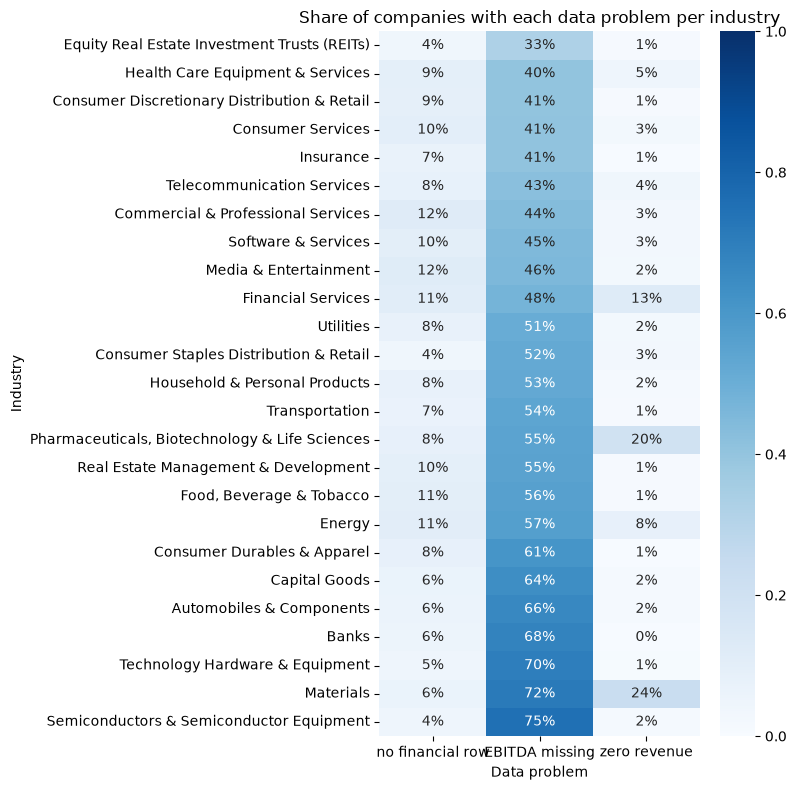

In [172]:
shares = pd.DataFrame({name: flag.groupby(data["industry"]).mean() for name, flag in flags.items()})
shares = shares.sort_values("EBITDA missing")

plt.figure(figsize=(8, 8))
sns.heatmap(shares, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1)
plt.title("Share of companies with each data problem per industry")
plt.xlabel("Data problem")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

The gaps are clearly not random. All p-values are close to 0, and the link is strongest for zero revenue (V = 0.32), then EBITDA missing (V = 0.23), while no financial row is small (V = 0.08).

In the plot we can see that zero revenue is most common in Materials (24%) and Pharma (20%). That makes sense to us, since mining and biotech companies often don't have any revenue yet. EBITDA is missing most often for Semiconductors (75%) and least often for REITs (33%).

So a gap is a signal here, and we want to keep it as a flag instead of just filling it in.

Country does not need its own row in the table. It is missing for exactly the companies in `no financial row`, so that row is already its test.

### What is the best way to fill the gaps?

A model needs a number in every cell, so we have to fill the gaps somehow. We can't drop those companies, because the final model has to predict every company. Dropping `ebitda_margin` would lose the information about which companies are missing it. And filling with the industry median is not allowed: industry is what we want to predict, so that would leak the answer.

That leaves the country median and the global median. To compare them, we hide 20% of the known values, fill them in with each rule and measure how far off we are. We do this in signed-log units (explained in the outlier part), so that a few giant values don't decide the result.

In [173]:
def signed_log(v):
    return np.sign(v) * np.log1p(np.abs(v))


rng = np.random.default_rng(0)
rows = []
for ratio in RATIOS:
    known = data[[ratio + "_clean", "country_code"]].dropna()
    hidden = rng.random(len(known)) < 0.2
    fit, test = known[~hidden], known[hidden]

    global_median = fit[ratio + "_clean"].median()
    grouped = fit.groupby("country_code")[ratio + "_clean"]
    country_median = grouped.median().where(grouped.count() >= 10)   # only countries with at least 10 values
    by_country = test["country_code"].map(country_median).fillna(global_median)

    truth = signed_log(test[ratio + "_clean"])
    rows.append({
        "ratio": ratio,
        "error global median": (truth - signed_log(global_median)).abs().mean(),
        "error country median": (truth - signed_log(by_country)).abs().mean(),
    })
display(pd.DataFrame(rows).set_index("ratio").round(4))

,error global median,error country median
ratio,,
net_profit_margin,0.3844,0.3817
ebitda_margin,0.6095,0.6038
asset_turnover,0.2870,0.2699


The country median is a bit better for all three ratios, but the difference is really small. For asset turnover, which has the biggest difference, the error goes from 0.287 to 0.270. So we stay with the global median, since it is simpler.

Filling gaps always makes the data look more certain than it is, because lots of companies get the same value. For EBITDA that is most of the rows. This is why every ratio also gets a **missing flag**, so the model can learn that the number was made up.

Country needs no filling rule. A company without a country just gets its own `unknown` category, which does the same job as the missing flag.

### Outliers

#### How bad is it?

A few huge values can completely destroy the mean and the standard deviation, while the median stays sensible. To count the outliers we use the **Tukey fence**: everything more than 3 × IQR beyond the quartiles counts as far out. The IQR is based on quartiles, so the outliers can't distort the rule that is supposed to find them. A rule based on the mean and standard deviation would have exactly this problem.

In [174]:
rows = []
for ratio in RATIOS:
    v = data[ratio + "_clean"].dropna()
    q1, q3 = v.quantile([0.25, 0.75])
    low, high = q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1)
    rows.append({"ratio": ratio, "mean": v.mean(), "std": v.std(), "median": v.median(),
                 "lower fence": low, "upper fence": high, "far out %": 100 * ((v < low) | (v > high)).mean()})
display(pd.DataFrame(rows).set_index("ratio").round(3))

,mean,std,median,lower fence,upper fence,far out %
ratio,,,,,,
net_profit_margin,1805.841,238732.848,0.038,-0.702,0.748,15.284
ebitda_margin,3323.686,361890.595,0.103,-1.178,1.311,15.637
asset_turnover,54.117,8176.109,0.465,-2.037,3.022,1.735


The mean net margin is about 1,806 while the median is 0.04, so the mean tells us nothing here. About 15% of the margins are far out, but only 1.7% of the asset turnovers.

### Are they errors?

We look at the most extreme companies first. If they are real, we would be deleting real information.

In [175]:
columns = ["industry", "country_code", "net_profit_margin_clean", "ebitda_margin_clean", "asset_turnover_clean"]
display(data.nlargest(5, "net_profit_margin_clean")[columns])
display(data.nsmallest(5, "net_profit_margin_clean")[columns])

,industry,country_code,net_profit_margin_clean,ebitda_margin_clean,asset_turnover_clean
22187,Materials,AUS,3.507696e+07,3.504681e+07,NaN
23760,Financial Services,CAN,5.335038e+06,-1.125820e+06,NaN
6544,Media & Entertainment,SWE,4.329286e+04,4.325621e+04,0.000006
20539,Materials,AUS,1.325072e+04,-5.512984e+03,0.000019
6819,"Pharmaceuticals, Biotechnology & Life Sciences",USA,8.437860e+03,8.516750e+03,0.001106


,industry,country_code,net_profit_margin_clean,ebitda_margin_clean,asset_turnover_clean
21759,Financial Services,USA,-145480.000000,NaN,0.000052
13153,Real Estate Management & Development,USA,-32113.666667,NaN,0.039735
7013,"Pharmaceuticals, Biotechnology & Life Sciences",USA,-31028.750000,-28513.500000,0.000128
15786,Energy,POL,-26810.928571,NaN,0.000165
18092,Consumer Services,SGP,-23813.333333,-19166.666667,0.000513


Most of these companies have an asset turnover close to 0, so their revenue is tiny compared to their assets. A margin divides by revenue, so a tiny revenue gives a giant number. These values are probably real, they are just not very useful: the company is not really that profitable, the ratio just blows up.

So we **shrink them instead of deleting them**, in two steps:

1. **Signed log**, `sign(v) * log(1 + |v|)`. This compresses huge values and keeps small ones almost the same. Unlike a normal log it also works for negative margins.
2. **Clipping** at the 1st and 99th percentile. Everything beyond that is set to the limit, so the company stays in the data but can't dominate it anymore.

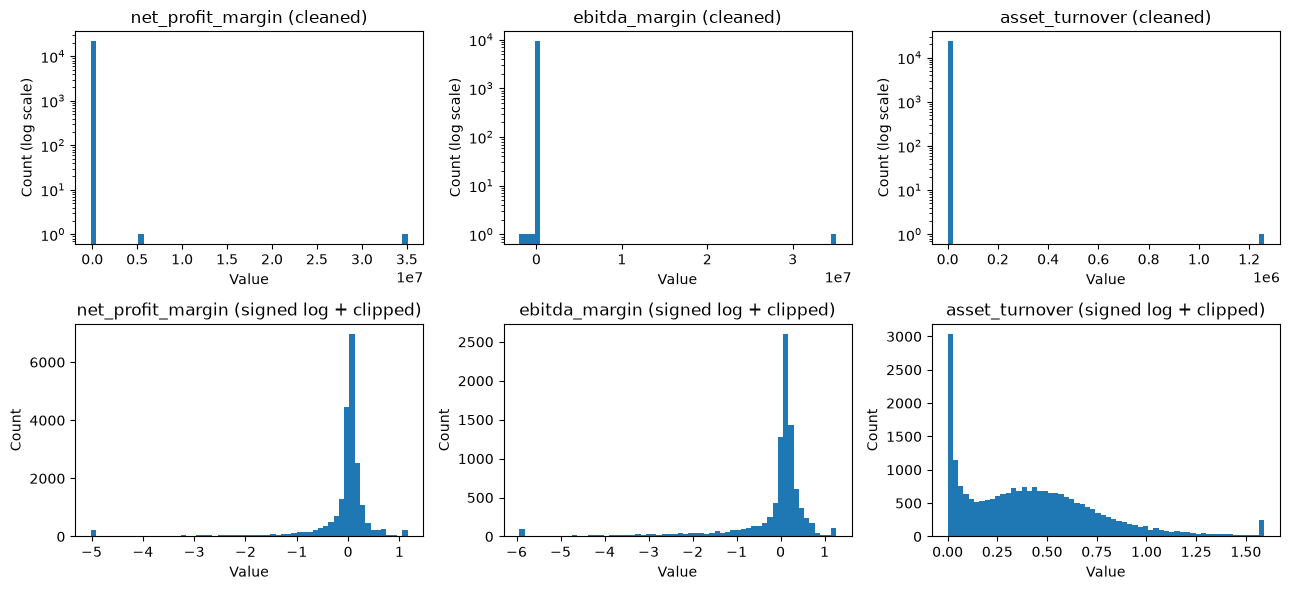

,net_profit_margin_scaled,ebitda_margin_scaled,asset_turnover_scaled
mean,-0.171,-0.243,0.418
std,0.862,1.143,0.342
median,0.037,0.098,0.382
min,-5.010,-5.936,0.000
max,1.157,1.255,1.592


In [176]:
plt.figure(figsize=(13, 6))

for i, ratio in enumerate(RATIOS):
    before = data[ratio + "_clean"].dropna()
    after = signed_log(before)
    after = after.clip(*after.quantile([0.01, 0.99]))
    data[ratio + "_scaled"] = after

    # Top row: cleaned values, bottom row: after the signed log and clipping
    plt.subplot(2, 3, i + 1)
    plt.hist(before, bins=60, log=True)
    plt.title(ratio + " (cleaned)")
    plt.xlabel("Value")
    plt.ylabel("Count (log scale)")

    plt.subplot(2, 3, i + 4)
    plt.hist(after, bins=60)
    plt.title(ratio + " (signed log + clipped)")
    plt.xlabel("Value")
    plt.ylabel("Count")

plt.tight_layout()
plt.show()

scaled = [r + "_scaled" for r in RATIOS]
display(data[scaled].agg(["mean", "std", "median", "min", "max"]).round(3))

In the top row almost all companies are in one bar, because a few extreme companies stretch the whole axis. After the signed log and the clipping we can actually see the shape of the data. The margins sit tightly around 0 with a long tail of companies making losses, while asset turnover is much more spread out.

The small peaks at the ends of the bottom plots are the clipped values, and the tall bar at 0 for asset turnover is mostly the zero-revenue companies. No company was removed, only the scale changed. The `mean` and `std` in the table also look sensible now.

### Outliers in country

A category has no extreme values, so the Tukey fence, the signed log and the clipping don't work here. The closest thing to an outlier is a country with very few companies. A model would get a whole column for that country, but almost nothing to learn from it.

We use the same idea as for the ratios: shrink, don't delete. These companies stay in the data, but in the `other` group. The plot shows the countries before and after.

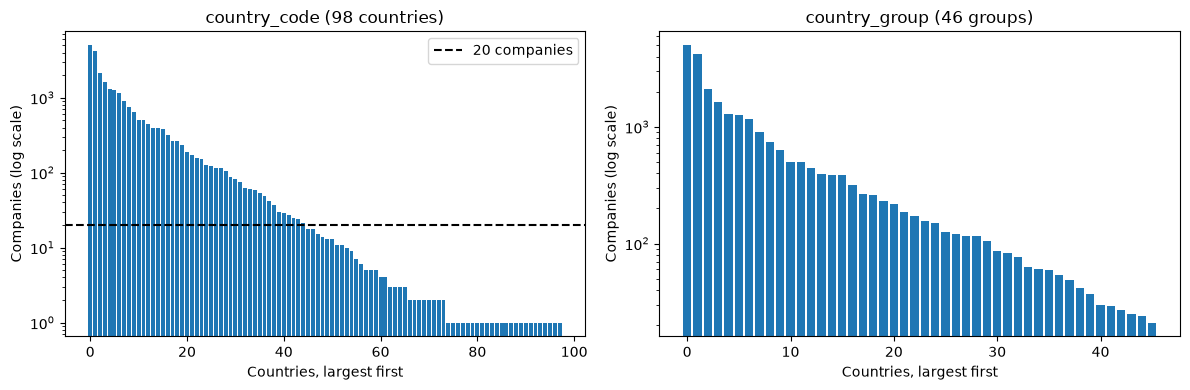

size of the other group: 220


In [177]:
groups = data["country_group"].value_counts()

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.bar(range(len(counts)), counts.values)
plt.axhline(MIN_COMPANIES, color="black", linestyle="--", label=f"{MIN_COMPANIES} companies")
plt.yscale("log")
plt.title(f"country_code ({len(counts)} countries)")
plt.xlabel("Countries, largest first")
plt.ylabel("Companies (log scale)")
plt.legend()

plt.subplot(1, 2, 2)
plt.bar(range(len(groups)), groups.values)
plt.yscale("log")
plt.title(f"country_group ({len(groups)} groups)")
plt.xlabel("Countries, largest first")
plt.ylabel("Companies (log scale)")

plt.tight_layout()
plt.show()

print("size of the other group:", groups["other"])

The 53 smallest countries end up in `other` together, with 220 companies in total. That leaves 46 groups, which is the same number of country columns a model would get.

### Do the financial distributions differ between industries?

#### The typical company in each industry

We use medians and quartiles here, because they are not really affected by outliers. All values are real observed values, so filled-in medians can't create fake differences.

In [178]:
summary = data.groupby("industry")[[r + "_clean" for r in RATIOS]].median()
summary.columns = RATIOS
summary.insert(0, "companies", data["industry"].value_counts())
display(summary.sort_values("asset_turnover").round(3))

,companies,net_profit_margin,ebitda_margin,asset_turnover
industry,,,,
Banks,947,0.246,0.249,0.037
Equity Real Estate Investment Trusts (REITs),422,0.251,0.570,0.083
Financial Services,1884,0.258,0.347,0.091
Real Estate Management & Development,898,0.075,0.220,0.130
Insurance,287,0.079,0.130,0.239
"Pharmaceuticals, Biotechnology & Life Sciences",1922,-0.185,-1.028,0.241
Utilities,569,0.083,0.301,0.269
Energy,1316,0.040,0.155,0.382
Materials,3917,0.025,0.077,0.401


The differences look very reasonable. Banks, REITs and Financial Services have the lowest asset turnover (0.04 to 0.09), since they have a lot of assets compared to their revenue. Retailers have the highest, with Consumer Staples Retail at 1.69. Pharma stands out with a median net margin of -0.19 and a median EBITDA margin of -1.03, so a typical company there is losing money.

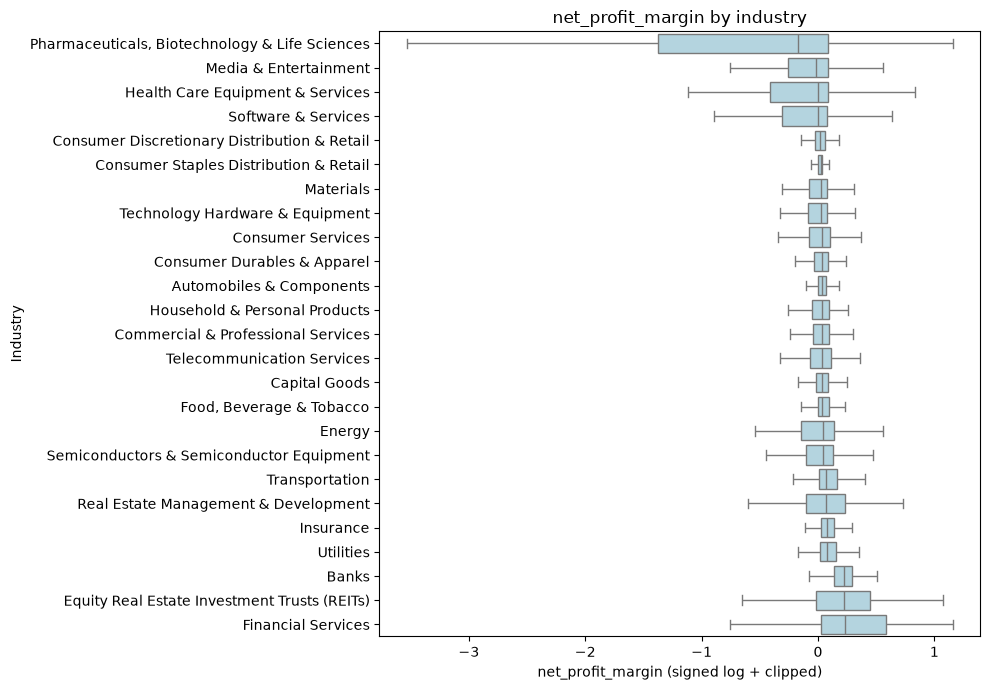

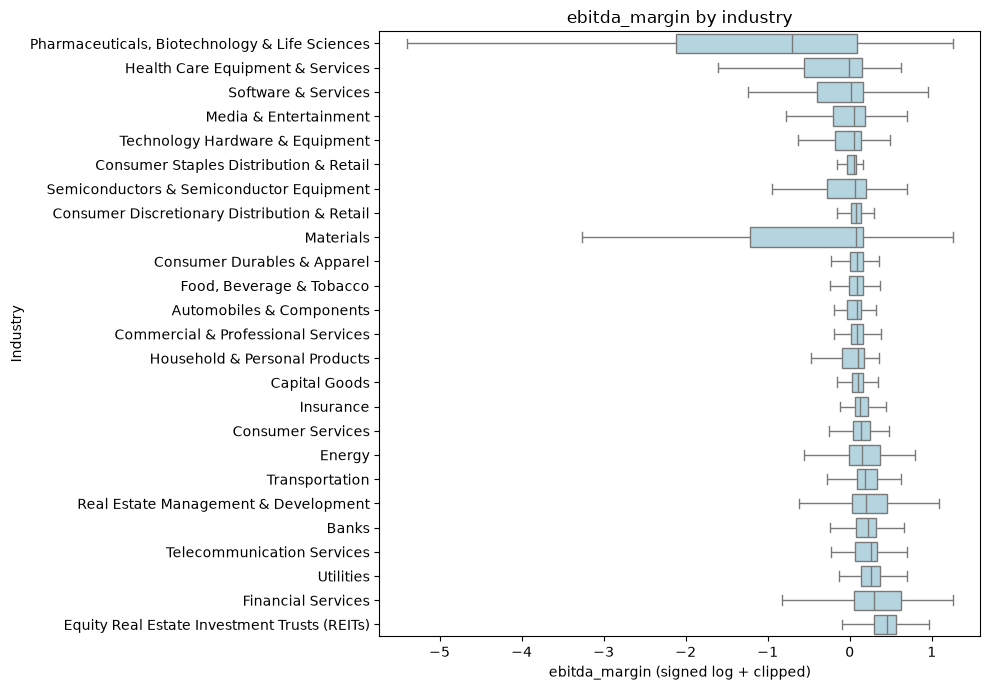

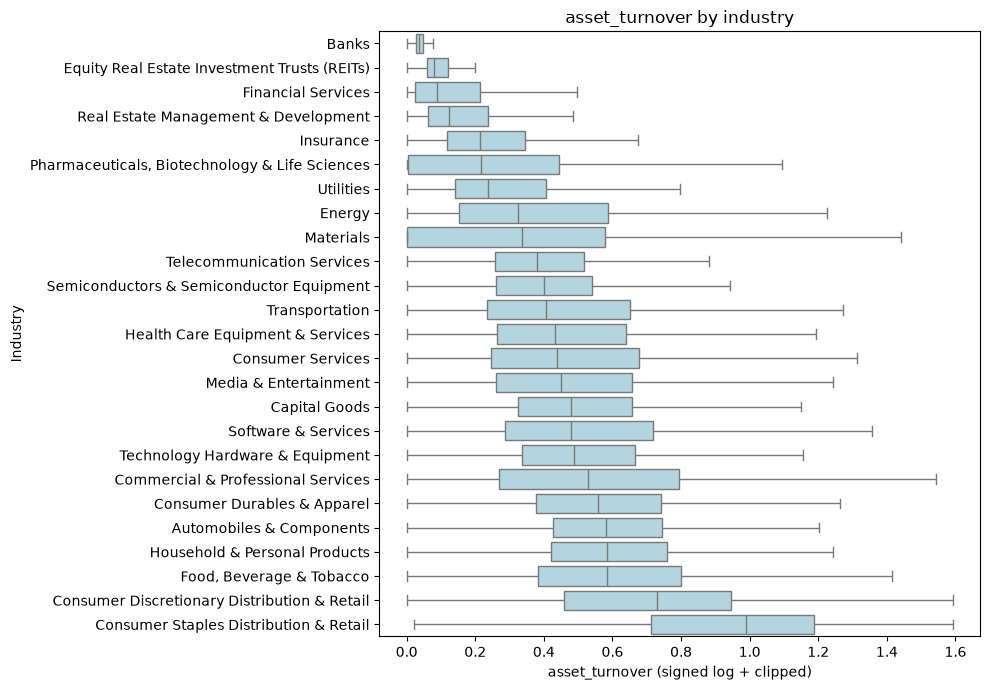

In [179]:
def plot_industry_distribution(ratio):
    # Sort the industries by their median, so the plot is easier to read
    order = data.groupby("industry")[ratio + "_scaled"].median().sort_values().index

    plt.figure(figsize=(10, 7))
    sns.boxplot(data=data, x=ratio + "_scaled", y="industry", order=order, showfliers=False, color="lightblue")
    plt.title(ratio + " by industry")
    plt.xlabel(ratio + " (signed log + clipped)")
    plt.ylabel("Industry")
    plt.tight_layout()
    plt.show()


for ratio in RATIOS:
    plot_industry_distribution(ratio)

We use the scaled values from the outlier part for these plots, since the boxes would be impossible to read otherwise. The box shows the middle 50% of the companies and the line in the box is the median.

Asset turnover shows the clearest differences, with the medians spread nicely from Banks to retail. For the margins most boxes sit close to 0. Pharma is the main exception on the low side, and Financial Services and REITs on the high side.

### Countries in each industry

A category has no median, so we describe the typical company differently: which country is most common in each industry, and which countries appear more often than we would expect.

For this we calculate how over-represented an industry is in a country: its share among the companies of that country, divided by its share among all companies. 1 means normal, 2 means the industry is twice as common in that country. We only show the 8 largest countries, because smaller countries have too few companies per industry.

In [180]:
known = data.dropna(subset=["country_group"])
country_mix = pd.crosstab(known["industry"], known["country_group"], normalize="index")
display(pd.DataFrame({"companies": known["industry"].value_counts(), "most common country": country_mix.idxmax(axis=1),
                      "share %": (100 * country_mix.max(axis=1)).round(1)}).sort_values("share %", ascending=False))

,companies,most common country,share %
industry,,,
Banks,892,USA,57.0
Health Care Equipment & Services,918,USA,38.8
"Pharmaceuticals, Biotechnology & Life Sciences",1763,USA,38.3
Equity Real Estate Investment Trusts (REITs),405,USA,32.6
Automobiles & Components,587,CHN,30.8
Insurance,266,USA,30.8
Capital Goods,2924,CHN,29.6
Financial Services,1671,USA,28.8
Household & Personal Products,209,USA,27.3


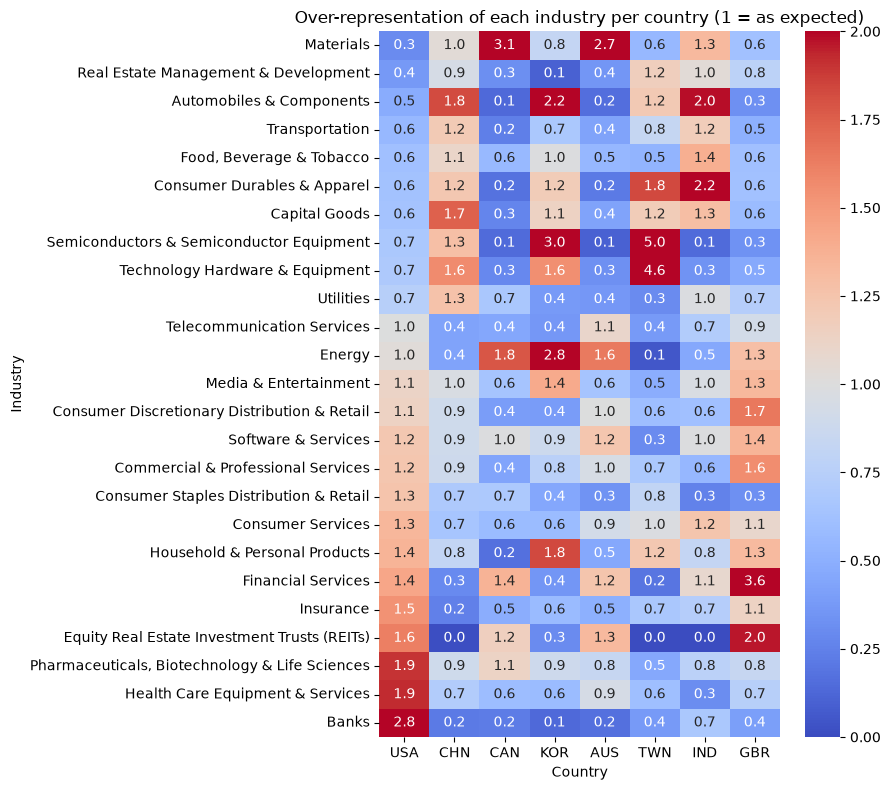

In [181]:
largest = counts.index[:8]
overall = known["industry"].value_counts(normalize=True)
lift = pd.crosstab(known["industry"], known["country_group"], normalize="columns")[largest].div(overall, axis=0)
lift = lift.sort_values(largest[0])

plt.figure(figsize=(9, 8))
sns.heatmap(lift, annot=True, fmt=".1f", cmap="coolwarm", center=1, vmin=0, vmax=2)
plt.title("Over-representation of each industry per country (1 = as expected)")
plt.xlabel("Country")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

There are some clear patterns. Taiwan has 5 times the usual share of Semiconductor companies and 4.6 times the share of Technology Hardware. Materials is common in Canada and Australia (3.1 and 2.7) and Financial Services in the UK (3.6). Banks are the most concentrated industry, 57% of them are in the USA. The color scale stops at 2, so everything above that has the same color.

### Are the differences significant?

We use the **Kruskal-Wallis test**. The null hypothesis is that all 25 industries come from the same distribution. It works like ANOVA but on ranks. ANOVA compares means and assumes roughly normal data, and the outlier part showed that neither makes sense here. With ranks, it doesn't matter how extreme an outlier is, only that it is the largest value.

With 27,000 companies almost every difference gets a tiny p-value, so we also look at the effect size. **Eta-squared** is the share of the variation in the ranks that is explained by the industry. As a rough guide, 0.01 is small, 0.06 is medium and 0.14 is large.

In [182]:
rows = []
for ratio in RATIOS:
    groups = [g.dropna().to_numpy() for _, g in data.groupby("industry")[ratio + "_clean"]]
    h, p = stats.kruskal(*groups)
    n, k = sum(len(g) for g in groups), len(groups)
    rows.append({"ratio": ratio, "companies": n, "H": h, "p": p, "eta squared": (h - k + 1) / (n - k)})
display(pd.DataFrame(rows).set_index("ratio").style.format({"p": "{:.1e}"}, precision=4))

,companies,H,p,eta squared
ratio,,,,
net_profit_margin,22088,2802.3110,0.0e+00,0.1259
ebitda_margin,9420,1804.3691,0.0e+00,0.1895
asset_turnover,23747,6028.2547,0.0e+00,0.2531


All three ratios differ between industries. Asset turnover is clearly the strongest (0.25), then EBITDA margin (0.19) and net margin (0.13). The EBITDA number only uses the 9,420 companies that have a real value.

For country we can't use Kruskal-Wallis, because it needs values that can be ranked and countries have no order. So we use the chi-square test and Cramér's V from the missing data part again.

Two things are different from before:

- The normal V gets pushed up if a table has many categories and few companies per cell, so we use the **bias-corrected** version. For the earlier flags this correction is too small to matter.
- With many categories V is not on the same scale as for the flags, and it can't be compared with eta-squared at all. So we add a second row, USA against the rest. It has two columns like the earlier flags, so those two can be compared.

Chi-square needs an expected count of about 5 per cell. The last column shows how many cells are below that.

In [183]:
def cramers_v(table):
    # Bias-corrected Cramer's V (Bergsma 2013)
    chi2 = stats.chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    r, c = table.shape
    phi2 = max(0, chi2 / n - (r - 1) * (c - 1) / (n - 1))
    r_corrected, c_corrected = r - (r - 1) ** 2 / (n - 1), c - (c - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / (min(r_corrected, c_corrected) - 1))


tables = {
    f"country ({known['country_group'].nunique()} groups)": pd.crosstab(known["industry"], known["country_group"]),
    f"{largest[0]} vs the rest": pd.crosstab(known["industry"], known["country_group"] == largest[0]),
}

rows = []
for name, table in tables.items():
    chi2, p, dof, expected = stats.chi2_contingency(table)
    rows.append({"variable": name, "chi2": chi2, "dof": dof, "p": p, "Cramer's V": cramers_v(table),
                 "cells with expected < 5 %": 100 * (expected < 5).mean()})
display(pd.DataFrame(rows).set_index("variable").style.format({"p": "{:.1e}"}, precision=3))

,chi2,dof,p,Cramer's V,cells with expected < 5 %
variable,,,,,
country (46 groups),14376.224,1080,0.0e+00,0.149,48.783
USA vs the rest,2340.846,24,0.0e+00,0.305,0.000


Country is clearly linked to industry. With all 46 groups V is 0.15, and USA against the rest gives 0.30, which is about as strong as the zero-revenue flag. 49% of the cells in the first row are below an expected count of 5, so we trust the second row more.

### Can the financials separate the industries our classifier confuses?

Kruskal-Wallis only tells us that some industries differ. For classification it matters more if the pairs our models mix up are different. The pairs below are some of the most frequent confusions of the ensemble.

We use the **Mann-Whitney U test** for each pair. Since we run a lot of tests, a few would look significant just by luck. The **Bonferroni correction** handles this by multiplying each p-value by the number of tests.

As effect size we use the **AUC**: the probability that a random company from the first industry has a higher value than one from the second. 0.5 means no separation, 1.0 or 0.0 means perfect separation. We get it directly from the test statistic with `AUC = U / (n1 * n2)`.

In [184]:
CONFUSED_PAIRS = [
    ("Capital Goods", "Materials"),
    ("Technology Hardware & Equipment", "Capital Goods"),
    ("Technology Hardware & Equipment", "Software & Services"),
    ("Health Care Equipment & Services", "Pharmaceuticals, Biotechnology & Life Sciences"),
    ("Energy", "Materials"),
    ("Commercial & Professional Services", "Capital Goods"),
    ("Commercial & Professional Services", "Software & Services"),
    ("Semiconductors & Semiconductor Equipment", "Technology Hardware & Equipment"),
    ("Consumer Discretionary Distribution & Retail", "Consumer Durables & Apparel"),
    ("Automobiles & Components", "Capital Goods"),
    ("Software & Services", "Financial Services"),
]

rows = []
for a, b in CONFUSED_PAIRS:
    for ratio in RATIOS:
        values_a = data.loc[data["industry"] == a, ratio + "_clean"].dropna()
        values_b = data.loc[data["industry"] == b, ratio + "_clean"].dropna()
        u, p = stats.mannwhitneyu(values_a, values_b)
        rows.append({"pair": f"{a} vs {b}", "ratio": ratio, "median first": values_a.median(),
                     "median second": values_b.median(), "AUC": u / (len(values_a) * len(values_b)), "p": p})

pairs = pd.DataFrame(rows)
pairs["p corrected"] = (pairs["p"] * len(pairs)).clip(upper=1)
pairs["significant"] = pairs["p corrected"] < 0.05
print(f"{pairs['significant'].sum()} of {len(pairs)} comparisons significant after correction")
display(pairs.pivot(index="pair", columns="ratio", values="AUC").loc[[f"{a} vs {b}" for a, b in CONFUSED_PAIRS], RATIOS].round(2))
display(pairs.assign(separation=(pairs["AUC"] - 0.5).abs()).nlargest(10, "separation")
        .drop(columns=["separation", "significant"]).style.format({"p": "{:.1e}", "p corrected": "{:.1e}"}, precision=3))

21 of 33 comparisons significant after correction


ratio,net_profit_margin,ebitda_margin,asset_turnover
pair,,,
Capital Goods vs Materials,0.56,0.57,0.65
Technology Hardware & Equipment vs Capital Goods,0.45,0.39,0.52
Technology Hardware & Equipment vs Software & Services,0.56,0.51,0.52
"Health Care Equipment & Services vs Pharmaceuticals, Biotechnology & Life Sciences",0.57,0.64,0.69
Energy vs Materials,0.55,0.65,0.55
Commercial & Professional Services vs Capital Goods,0.49,0.50,0.53
Commercial & Professional Services vs Software & Services,0.59,0.61,0.53
Semiconductors & Semiconductor Equipment vs Technology Hardware & Equipment,0.55,0.55,0.38
Consumer Discretionary Distribution & Retail vs Consumer Durables & Apparel,0.46,0.48,0.64


,pair,ratio,median first,median second,AUC,p,p corrected
32,Software & Services vs Financial Services,asset_turnover,0.613,0.091,0.814,2.3e-181,7.5e-180
30,Software & Services vs Financial Services,net_profit_margin,-0.002,0.258,0.240,7.6e-119,2.5e-117
31,Software & Services vs Financial Services,ebitda_margin,0.016,0.347,0.242,3.2e-65,1.1e-63
11,"Health Care Equipment & Services vs Pharmaceuticals, Biotechnology & Life Sciences",asset_turnover,0.542,0.241,0.694,7.0e-59,2.3e-57
2,Capital Goods vs Materials,asset_turnover,0.612,0.401,0.651,3.5e-95,1.1e-93
13,Energy vs Materials,ebitda_margin,0.155,0.077,0.646,1.8e-17,5.9e-16
10,"Health Care Equipment & Services vs Pharmaceuticals, Biotechnology & Life Sciences",ebitda_margin,-0.014,-1.028,0.642,3.0e-17,9.8e-16
26,Consumer Discretionary Distribution & Retail vs Consumer Durables & Apparel,asset_turnover,1.076,0.749,0.640,2.3e-20,7.6e-19
23,Semiconductors & Semiconductor Equipment vs Technology Hardware & Equipment,asset_turnover,0.491,0.630,0.383,3.6e-16,1.2e-14
19,Commercial & Professional Services vs Software & Services,ebitda_margin,0.098,0.016,0.610,5.8e-09,1.9e-07


21 of the 33 comparisons are significant. The best one by far is Software & Services vs Financial Services with asset turnover (AUC 0.81). Health Care vs Pharma (0.69) and Capital Goods vs Materials (0.65) also separate okay with asset turnover. Others barely separate at all, for example Commercial & Professional Services vs Capital Goods (0.49 to 0.53).

Even an AUC of 0.65 still means a lot of overlap, so the financials alone can't tell these industries apart. They can only give the model a small hint.

We do the same for country. Mann-Whitney also needs values that can be ranked, so each pair gets a chi-square test and the bias-corrected V instead, with the Bonferroni correction for 11 tests.

V can't be compared with the AUC above, and many cells are small here, so this is mostly useful as a ranking of the pairs. The last columns show the country whose share is furthest apart between the two industries.

In [185]:
rows = []
for a, b in CONFUSED_PAIRS:
    subset = known[known["industry"].isin([a, b])]
    table = pd.crosstab(subset["country_group"], subset["industry"])
    p = stats.chi2_contingency(table)[1]
    shares_by_country = table / table.sum()
    gap = (shares_by_country[a] - shares_by_country[b]).abs().idxmax()
    rows.append({"pair": f"{a} vs {b}", "Cramer's V": cramers_v(table), "p corrected": min(p * len(CONFUSED_PAIRS), 1),
                 "biggest gap": gap, "share first %": 100 * shares_by_country.loc[gap, a],
                 "share second %": 100 * shares_by_country.loc[gap, b]})

country_pairs = pd.DataFrame(rows).set_index("pair").sort_values("Cramer's V", ascending=False)
print(f"{(country_pairs['p corrected'] < 0.05).sum()} of {len(country_pairs)} pairs significant after correction")
display(country_pairs.style.format({"p corrected": "{:.1e}"}, precision=2))

11 of 11 pairs significant after correction


,Cramer's V,p corrected,biggest gap,share first %,share second %
pair,,,,,
Capital Goods vs Materials,0.44,1.1e-248,CAN,2.33,26.40
Technology Hardware & Equipment vs Software & Services,0.44,3.0e-98,TWN,23.39,1.53
Energy vs Materials,0.38,3.6e-123,USA,20.70,6.11
Consumer Discretionary Distribution & Retail vs Consumer Durables & Apparel,0.35,1.5e-29,USA,22.78,12.57
Software & Services vs Financial Services,0.31,1.2e-45,CHN,15.12,4.97
Technology Hardware & Equipment vs Capital Goods,0.30,4.0e-65,TWN,23.39,6.02
Commercial & Professional Services vs Capital Goods,0.29,1.9e-47,CHN,15.06,29.62
"Health Care Equipment & Services vs Pharmaceuticals, Biotechnology & Life Sciences",0.21,1.7e-15,CAN,5.01,9.64
Commercial & Professional Services vs Software & Services,0.17,1.8e-06,CAN,3.69,8.43


All 11 pairs are significant. The strongest are Capital Goods vs Materials, where Canada is 2% against 26%, and Technology Hardware vs Software & Services, where Taiwan is 23% against 2%. The weakest is Automobiles vs Capital Goods.

### Ensemble: which input features are worth using?

Now we build the model that we submit. We compare the single models with several versions of a soft-vote ensemble to see what each input feature adds. They all use the same train and validation split as the models above.

With 5-fold cross-validation and seven feature sets this would take 2 to 3 hours, which is too long for this notebook. So every model is trained once, and we use a bootstrap on the validation set to see if a difference is real.

`reindex` puts the financial table in the same order as `df`, and companies without financial data get an empty row, which is handled as missing later on.

In [186]:
fin = df_fin.reindex(df["id"].values).reset_index(drop=True)
print("companies without financial data:", fin["country_code"].isna().sum())

companies without financial data: 2206


In [187]:
def score_from_probabilities(y_true, P):
    """Prediction = most likely class. Confidence = its probability."""
    # clip because averaged probabilities can end up slightly above 1 through rounding
    return confidence_score(y_true, P.argmax(axis=1), P.max(axis=1).clip(0, 1))

### Extra features: country and financial ratios

Each input can be switched on or off, so that we can test them separately. `ExtraFeatures` gets a list with these groups:

- `country`: the one-hot country columns.
- `net_profit_margin`, `ebitda_margin`, `asset_turnover`: the scaled ratio, a missing flag and a zero-revenue flag for this ratio.
- `zero_revenue`: only one flag for zero revenue, without any ratio.
- `no_row`: one flag for companies without financial data.

All statistics (percentiles, medians, scaling, country categories) are learned in `fit` from the training rows only and then reused in `transform`. If we calculated them on all rows, information from the test rows would leak into the training.

The ratios are handled the same way as in the analysis above:

- An `inf` margin or an asset turnover of 0 means zero revenue, so the company gets a zero-revenue flag.
- A negative asset turnover is treated as missing.
- Missing values get the median plus a missing flag. EBITDA alone is missing for about 65% of the companies.
- Extreme outliers are compressed with a signed log and then clipped at the 1st and 99th percentile of the training rows.

Country becomes one-hot columns, and countries with fewer than 20 companies are grouped together.

In [188]:
class ExtraFeatures:
    def __init__(self, groups):
        self.groups = groups

    def _country(self, fin):
        return fin["country_code"].fillna("unknown").to_numpy().reshape(-1, 1)

    def _clean_ratio(self, fin, ratio):
        v = fin[ratio].to_numpy(dtype=float).copy()
        zero_revenue = (v == 0) if ratio == "asset_turnover" else np.isinf(v)
        if ratio == "asset_turnover":
            v[v < 0] = np.nan
        v[np.isinf(v)] = np.nan
        missing = np.isnan(v)
        signed_log = np.sign(v) * np.log1p(np.abs(v))
        return signed_log, missing, zero_revenue

    def _zero_revenue(self, fin):
        net_margin = fin["net_profit_margin"].to_numpy(dtype=float)
        turnover = fin["asset_turnover"].to_numpy(dtype=float)
        return np.isinf(net_margin) | (turnover == 0)

    def fit(self, fin):
        if "country" in self.groups:
            self.encoder = OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist",
                                         sparse_output=False).fit(self._country(fin))
        self.stats = {}
        for ratio in RATIOS:
            if ratio in self.groups:
                s, missing, _ = self._clean_ratio(fin, ratio)
                low, high = np.nanquantile(s, [0.01, 0.99])
                s = np.clip(s, low, high)
                median = np.nanmedian(s)
                s[missing] = median
                self.stats[ratio] = (low, high, median, s.mean(), s.std())
        return self

    def transform(self, fin):
        columns = []
        for group in self.groups:
            if group == "country":
                columns.append(self.encoder.transform(self._country(fin)))
            elif group == "no_row":
                columns.append(fin["country_code"].isna().to_numpy(dtype=float).reshape(-1, 1))
            elif group == "zero_revenue":
                columns.append(self._zero_revenue(fin).astype(float).reshape(-1, 1))
            else:
                low, high, median, mean, std = self.stats[group]
                s, missing, zero_revenue = self._clean_ratio(fin, group)
                s = np.clip(s, low, high)
                s[missing] = median
                columns.append(np.column_stack([(s - mean) / std, missing, zero_revenue]).astype(float))
        return np.hstack(columns)

### The models

We use three models that work quite differently, so they hopefully make different mistakes:

- **Logistic regression** is linear and captures the broad directions in the embedding space.
- **kNN** looks at the most similar companies, so it can pick up small local clusters.
- **MLP** is non-linear and can combine features in ways a straight boundary can't.

kNN always uses only the embedding, because extra 0/1 columns would distort the cosine distance between the descriptions. Its embeddings are centered and normalized again, so that the distance focuses on what differs between companies.

In [189]:
def predict_lr(X_train, y_train, X_test, C=3):
    return LogisticRegression(C=C, max_iter=3000).fit(X_train, y_train).predict_proba(X_test)


def predict_knn(X_train, y_train, X_test):
    mean_embedding = X_train.mean(axis=0)

    def center(Z):
        Z = Z - mean_embedding
        return Z / np.linalg.norm(Z, axis=1, keepdims=True)

    knn = KNeighborsClassifier(n_neighbors=15, metric="cosine", weights=lambda d: np.exp(-10 * d))
    return knn.fit(center(X_train), y_train).predict_proba(center(X_test))


def predict_mlp(X_train, y_train, X_test, seeds, progress, label):
    P = 0
    for seed in range(seeds):
        mlp = make_pipeline(
            StandardScaler(),
            MLPClassifier(hidden_layer_sizes=(512,), alpha=1e-2, early_stopping=True, random_state=seed),
        )
        P = P + mlp.fit(X_train, y_train).predict_proba(X_test) / seeds
        progress.step(f"{label}: MLP seed {seed + 1}/{seeds}")
    return P


def soft_vote(*probabilities):
    return sum(probabilities) / len(probabilities)

### Shared experiment code

`run_all_models` trains every model on one set of training rows and predicts the test rows.

`Progress` prints a line after each finished step, with the percentage done and a rough guess of the time left.

In [190]:
FEATURE_SETS = {
    "embedding only": [],
    "embedding + country": ["country"],
    "embedding + country + net margin": ["country", "net_profit_margin"],
    "embedding + country + EBITDA margin": ["country", "ebitda_margin"],
    "embedding + country + asset turnover": ["country", "asset_turnover"],
    "embedding + country + zero revenue": ["country", "zero_revenue"],
    "embedding + country + financials": ["country", "no_row", "net_profit_margin", "ebitda_margin", "asset_turnover"],
}


class Progress:
    def __init__(self, total_steps):
        self.total = total_steps
        self.done = 0
        self.start = time.time()

    def step(self, text):
        self.done += 1
        elapsed = (time.time() - self.start) / 60
        remaining = elapsed / self.done * (self.total - self.done)
        print(f"[{self.done}/{self.total} | {self.done / self.total:.0%}] {text} | "
              f"elapsed {elapsed:.1f} min, about {remaining:.1f} min left", flush=True)


def steps_per_run(seeds):
    return 2 + len(FEATURE_SETS) * (1 + seeds)


def run_all_models(train_idx, test_idx, seeds, progress, label):
    X_train, y_train, X_test = X[train_idx], y[train_idx], X[test_idx]
    probabilities = {}

    probabilities["LR C=1 (baseline)"] = predict_lr(X_train, y_train, X_test, C=1)
    progress.step(f"{label}: baseline LR")
    P_knn = predict_knn(X_train, y_train, X_test)
    probabilities["kNN"] = P_knn
    progress.step(f"{label}: kNN")

    for name, groups in FEATURE_SETS.items():
        if not groups:
            F_train, F_test = X_train, X_test
        else:
            extra = ExtraFeatures(groups).fit(fin.iloc[train_idx])
            F_train = np.hstack([X_train, extra.transform(fin.iloc[train_idx])])
            F_test = np.hstack([X_test, extra.transform(fin.iloc[test_idx])])

        P_lr = predict_lr(F_train, y_train, F_test)
        progress.step(f"{label}: {name}: LR")
        P_mlp = predict_mlp(F_train, y_train, F_test, seeds, progress, f"{label}: {name}")

        probabilities[f"LR C=3 | {name}"] = P_lr
        probabilities[f"MLP | {name}"] = P_mlp
        probabilities[f"Ensemble | {name}"] = soft_vote(P_lr, P_knn, P_mlp)

    return probabilities

### Comparing the models on the validation set

Each model is trained once on the train split. The score moves by about +/-0.01 depending on which companies land in the validation set, so we shouldn't trust small differences in this table.

In [191]:
progress = Progress(steps_per_run(MLP_SEEDS))
probabilities = run_all_models(train_idx, val_idx, MLP_SEEDS, progress, "comparison")

[1/30 | 3%] comparison: baseline LR | elapsed 0.1 min, about 2.5 min left
[2/30 | 7%] comparison: kNN | elapsed 0.1 min, about 1.6 min left
[3/30 | 10%] comparison: embedding only: LR | elapsed 0.3 min, about 2.3 min left
[4/30 | 13%] comparison: embedding only: MLP seed 1/3 | elapsed 0.9 min, about 5.6 min left
[5/30 | 17%] comparison: embedding only: MLP seed 2/3 | elapsed 1.6 min, about 7.8 min left
[6/30 | 20%] comparison: embedding only: MLP seed 3/3 | elapsed 2.3 min, about 9.2 min left
[7/30 | 23%] comparison: embedding + country: LR | elapsed 2.4 min, about 8.0 min left
[8/30 | 27%] comparison: embedding + country: MLP seed 1/3 | elapsed 3.3 min, about 9.1 min left
[9/30 | 30%] comparison: embedding + country: MLP seed 2/3 | elapsed 4.0 min, about 9.4 min left
[10/30 | 33%] comparison: embedding + country: MLP seed 3/3 | elapsed 4.8 min, about 9.6 min left
[11/30 | 37%] comparison: embedding + country + net margin: LR | elapsed 4.9 min, about 8.5 min left
[12/30 | 40%] comparis

In [192]:
comparison = pd.DataFrame([
    {"model": name, "F1": f1_score(y_val, P.argmax(axis=1), average="weighted"),
     "score": score_from_probabilities(y_val, P)}
    for name, P in probabilities.items()
]).set_index("model")
comparison["gain vs baseline"] = comparison["score"] - comparison.loc["LR C=1 (baseline)", "score"]
comparison.sort_values("score", ascending=False).round(4)

,F1,score,gain vs baseline
model,,,
Ensemble | embedding + country + financials,0.7612,0.6522,0.0369
Ensemble | embedding + country + asset turnover,0.7609,0.6512,0.0359
Ensemble | embedding + country + EBITDA margin,0.7587,0.6502,0.0349
Ensemble | embedding + country + net margin,0.7580,0.6490,0.0338
Ensemble | embedding + country,0.7578,0.6490,0.0337
Ensemble | embedding + country + zero revenue,0.7584,0.6487,0.0334
MLP | embedding + country + financials,0.7548,0.6445,0.0292
Ensemble | embedding only,0.7537,0.6442,0.0290
MLP | embedding + country + net margin,0.7517,0.6393,0.0240


TODO after the run: write what we see in the table here.

#### Do the extra features really help?

We only have one validation set, so we bootstrap it: we draw the validation companies again with replacement, 1000 times, and calculate the score of two ensembles on the same draw. This shows how much the gain moves depending on which companies are in the validation set. It doesn't show how much it moves with a different training set, so we stay careful with small gains.

In [193]:
N_BOOT = 1000
rng = np.random.default_rng(0)
draws = [rng.integers(0, len(y_val), len(y_val)) for _ in range(N_BOOT)]


def bootstrap_gain(P, P_base):
    return np.array([score_from_probabilities(y_val[d], P[d]) - score_from_probabilities(y_val[d], P_base[d])
                     for d in draws])


rows = []
for name in FEATURE_SETS:
    P = probabilities[f"Ensemble | {name}"]
    gain = bootstrap_gain(P, probabilities["Ensemble | embedding only"])
    gain_country = bootstrap_gain(P, probabilities["Ensemble | embedding + country"])
    rows.append({"ensemble": name, "score": score_from_probabilities(y_val, P),
                 "gain vs embedding only": gain.mean(),
                 "low": np.quantile(gain, 0.025), "high": np.quantile(gain, 0.975),
                 "gain vs country": gain_country.mean(),
                 "low (country)": np.quantile(gain_country, 0.025),
                 "high (country)": np.quantile(gain_country, 0.975)})
display(pd.DataFrame(rows).set_index("ensemble").round(4))

,score,gain vs embedding only,low,high,gain vs country,low (country),high (country)
ensemble,,,,,,,
embedding only,0.6442,0.0000,0.0000,0.0000,-0.0047,-0.0104,0.0009
embedding + country,0.6490,0.0047,-0.0009,0.0104,0.0000,0.0000,0.0000
embedding + country + net margin,0.6490,0.0047,-0.0005,0.0097,-0.0000,-0.0046,0.0048
embedding + country + EBITDA margin,0.6502,0.0060,0.0008,0.0114,0.0013,-0.0036,0.0058
embedding + country + asset turnover,0.6512,0.0069,0.0018,0.0118,0.0022,-0.0023,0.0065
embedding + country + zero revenue,0.6487,0.0045,-0.0013,0.0101,-0.0002,-0.0055,0.0047
embedding + country + financials,0.6522,0.0079,0.0026,0.0134,0.0032,-0.0022,0.0085


TODO after the run: write which features we pick and why.

In [ ]:

FINAL_FEATURES = "embedding + country + asset turnover"

## Uncertainty quantification & Flagging uncertain ones & Relationship between confidence and accuracy

Create uncertainty quantification framework using p-values or other statistical measures to:
- Assess prediction confidence
- Flag uncertain classifications for potential human review
- Analyze the relationship between statistical confidence and classification accuracy



We use the ensemble with `FINAL_FEATURES`, trained on the train split, so these numbers are for companies it has not seen. The model we submit has the same setup but is trained on all rows.

In [195]:
P_val = probabilities[f"Ensemble | {FINAL_FEATURES}"]
y_pred = P_val.argmax(axis=1)
confidence = P_val.max(axis=1).clip(0, 1)
correct = y_pred == y_val

print(f"Validation accuracy: {correct.mean():.3f}")
print(f"confidence_score: {confidence_score(y_val, y_pred, confidence):.3f}")

Validation accuracy: 0.762
confidence_score: 0.649


TODO after the run: write what we see here.


### p-Values to assess prediction confidence

The p-value only looks at the embedding, even if the ensemble also uses extra features.

In [196]:

def class_centers(X_train, y_train):
    """Compute the mean embedding for each class."""
    X_train = np.asarray(X_train, dtype=float)
    y_train = np.asarray(y_train)

    centers = {}
    for class_label in np.unique(y_train):
        class_mask = y_train == class_label
        center = X_train[class_mask].mean(axis=0)
        centers[class_label] = center

    return centers



def cosine_distance(a, b):
    """Compute the cosine distance between two vectors."""
    similarity = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return 1 - similarity

def get_cosine_distances_to_class_centers(X_train, y_train, centers): 
    """Compute each sample's cosine distance to its class mean embedding."""
    distances = {class_id: [] for class_id in np.unique(y_train)}

    for sample in range(len(X_train)): 
        class_label = y_train[sample] 
        center = centers[class_label] 
        dist = cosine_distance(X_train[sample], center) 
        distances[class_label].append(dist)
    return distances



def get_class_distribution_stats(X_train, y_train):
    """Compute the mean and std of the cosine distances to the class mean embedding for each class."""
    centers = class_centers(X_train, y_train) 
    distances_per_class = get_cosine_distances_to_class_centers(X_train, y_train, centers)

    # get mean and std of distances for each class
    class_distribution_stats = {}
    for class_id, distances in distances_per_class.items():
        mean_distance = np.mean(distances)
        std_distance = np.std(distances)
        class_distribution_stats[class_id] = (mean_distance, std_distance, centers[class_id])  # Include the class center in the stats

    return class_distribution_stats


class_distribution_stats = get_class_distribution_stats(X_train, y_train)
print("Class distribution stats (mean, std) of cosine distances to class centers:")
for class_id, (mean_distance, std_distance, center) in class_distribution_stats.items():
    print(f"Class {class_id}: mean distance = {mean_distance:.4f}, std distance = {std_distance:.4f}")



Class distribution stats (mean, std) of cosine distances to class centers:
Class 0: mean distance = 0.2380, std distance = 0.0863
Class 1: mean distance = 0.1052, std distance = 0.0719
Class 2: mean distance = 0.2966, std distance = 0.0883
Class 3: mean distance = 0.3167, std distance = 0.0875
Class 4: mean distance = 0.2580, std distance = 0.0880
Class 5: mean distance = 0.2983, std distance = 0.0924
Class 6: mean distance = 0.3026, std distance = 0.0975
Class 7: mean distance = 0.2345, std distance = 0.0959
Class 8: mean distance = 0.2860, std distance = 0.1274
Class 9: mean distance = 0.2143, std distance = 0.0836
Class 10: mean distance = 0.2516, std distance = 0.1000
Class 11: mean distance = 0.2807, std distance = 0.0894
Class 12: mean distance = 0.3299, std distance = 0.1034
Class 13: mean distance = 0.2642, std distance = 0.1023
Class 14: mean distance = 0.1677, std distance = 0.0802
Class 15: mean distance = 0.2996, std distance = 0.0982
Class 16: mean distance = 0.2849, std d


Check if distances are normally distributed for each class

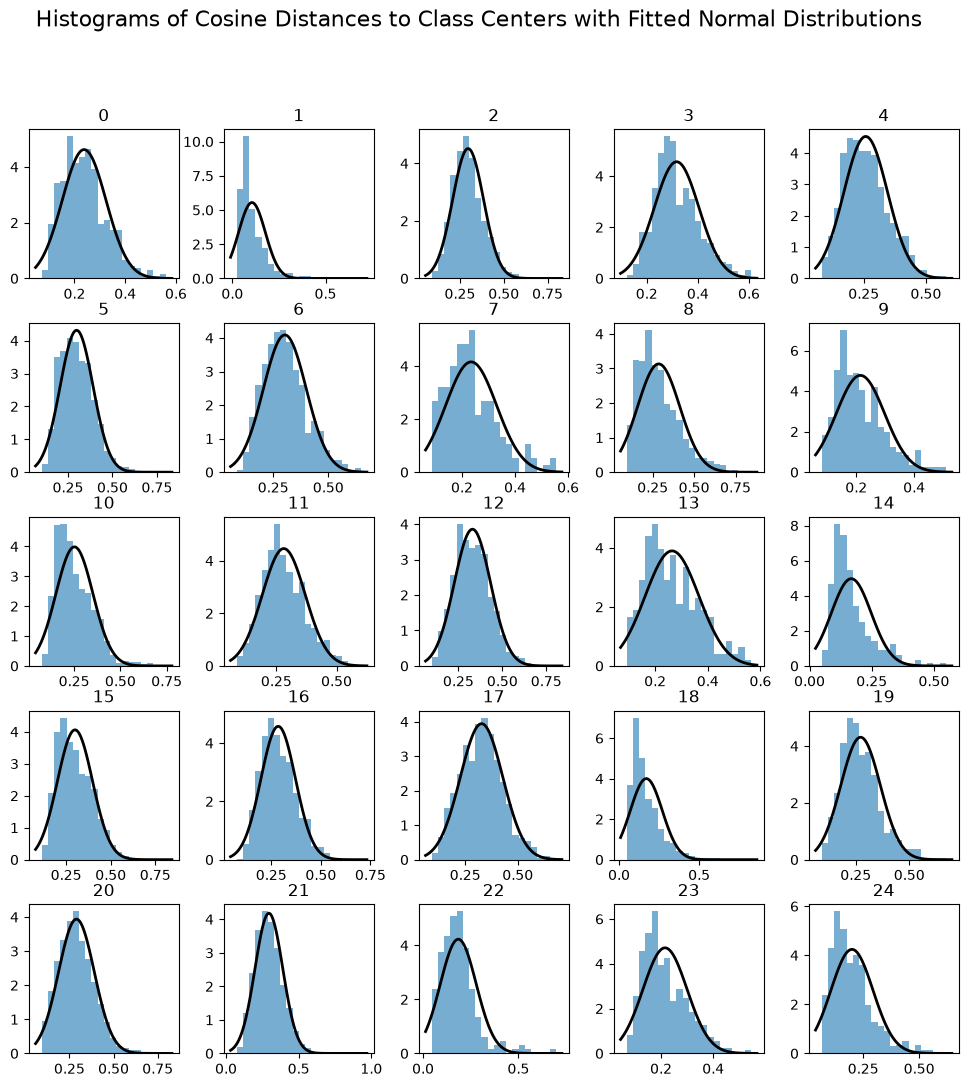

In [197]:

centers = class_centers(X_train, y_train) 
distances_per_class = get_cosine_distances_to_class_centers(X_train, y_train, centers)

plt.figure(figsize=(12, 12))
plt.suptitle("Histograms of Cosine Distances to Class Centers with Fitted Normal Distributions", fontsize=16)
plt.subplots_adjust(wspace=0.3, hspace=0.3)

# Plot histograms fo distances for each class as a grid (subplots)
for class_id, distances in distances_per_class.items():
    plt.subplot(5, 5, class_id + 1)
    plt.hist(distances, bins=20, density=True, alpha=0.6)
    
    # Fit a normal distribution to the data
    mu, std = norm.fit(distances)
    
    # Plot the PDF of the fitted normal distribution
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)
    p = norm.pdf(x, mu, std)
    plt.plot(x, p, 'k', linewidth=2)
    
    plt.title(class_id)


We can see that the distances to the class centers are mostly following normal distributions. Not all perfectly though. 
Some classes are more closely clustered than others. 

1-cosine similarity results in a range of [0,2], where 0 indicates identical vectors and 2 indicates vectors pointing in the opposite directions.

In [198]:
# p value of a prediction based on class distribution stats 
def compute_p_value(predicted_class, sample_embedding, class_distribution_stats):
    """Compute the p-value of a prediction based on class distribution stats."""
    mean_distance, std_distance, center = class_distribution_stats[predicted_class]
    distance = cosine_distance(sample_embedding, center)
    
    # Compute the z-score
    z_score = (distance - mean_distance) / std_distance
    
    # Compute the p-value from the z-score
    p_value = 1 - norm.cdf(z_score)  # One-tailed test
    return p_value

In [199]:

# for a sample prediction 
compute_p_value(predicted_class=y_pred[0], sample_embedding=X_val[0], class_distribution_stats=class_distribution_stats)

np.float64(0.9067151902138818)

### Flag uncertain predictions based on p-values

In [200]:
def flag_prediction_based_on_p_value(predicted_class, sample_embedding, class_distribution_stats, alpha=0.05):
    """Flag a prediction as potentially incorrect based on its p-value."""
    p_value = compute_p_value(predicted_class, sample_embedding, class_distribution_stats)
    return p_value < alpha, p_value  # Flag if p-value is less than the significance level

In [201]:
# Tune to match quality or time constraints
alpha = 0.1  # Significance level for flagging predictions
results = []

for X_sample, y_sample, predicted_class in zip(X_val, y_val, y_pred):
    is_flagged, p_value = flag_prediction_based_on_p_value(
        predicted_class,
        X_sample,
        class_distribution_stats,
        alpha
    )

    results.append({
        "true_class": y_sample,
        "predicted_class": predicted_class,
        "flagged": is_flagged,
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

results_df.head(10)

,true_class,predicted_class,flagged,p_value
0,10,10,False,0.906715
1,13,17,False,0.431946
2,10,10,False,0.117720
3,1,1,False,0.779125
4,17,17,False,0.139370
5,0,2,False,0.269434
6,21,19,False,0.126622
7,11,11,False,0.922034
8,17,17,False,0.855392
9,2,8,False,0.770633


We can also flag with the confidence of the model, for example the least confident 20% of the predictions. Here we compare both rules.

In [202]:
flagged_p_value = results_df["flagged"].to_numpy()
flagged_confidence = confidence < np.quantile(confidence, 0.2)

rows = []
for name, flagged in {f"p-value < {alpha}": flagged_p_value, "lowest 20% confidence": flagged_confidence}.items():
    rows.append({"rule": name, "flagged %": 100 * flagged.mean(),
                 "accuracy flagged": correct[flagged].mean(),
                 "accuracy not flagged": correct[~flagged].mean()})
display(pd.DataFrame(rows).set_index("rule").round(3))
print("flagged by both rules:", (flagged_p_value & flagged_confidence).sum())

,flagged %,accuracy flagged,accuracy not flagged
rule,,,
p-value < 0.1,6.966,0.640,0.771
lowest 20% confidence,20.015,0.436,0.843


flagged by both rules: 77


TODO after the run: write which rule works better here.

### Relationship between statistical confidence and classification accuracy

We can analyze two things here: 1. The relationship between the p-value and the accuracy of predictions and 2. the relationship of the model's confidence of a prediction and the accuracy of predictions.

The second one is important if we want to check if we have a calibrated classifier. That means if the models predicted probability matches the accuracy it achieves. E.g. if the model chooses a class with a mean probability of 0.8 but only achieves an accuracy of 0.6 then it is overconfident. Ideally we want to assign probabilities to classes that reflect reality. 

,count,mean_p_value,accuracy
bin,,,
"(-0.001, 0.1]",189,0.048514,0.640212
"(0.1, 0.2]",177,0.150582,0.700565
"(0.2, 0.3]",227,0.251113,0.709251
"(0.3, 0.4]",235,0.354201,0.723404
"(0.4, 0.5]",251,0.449235,0.725100
"(0.5, 0.6]",286,0.551161,0.734266
"(0.6, 0.7]",343,0.651054,0.804665
"(0.7, 0.8]",387,0.754340,0.808786
"(0.8, 0.9]",419,0.848191,0.828162


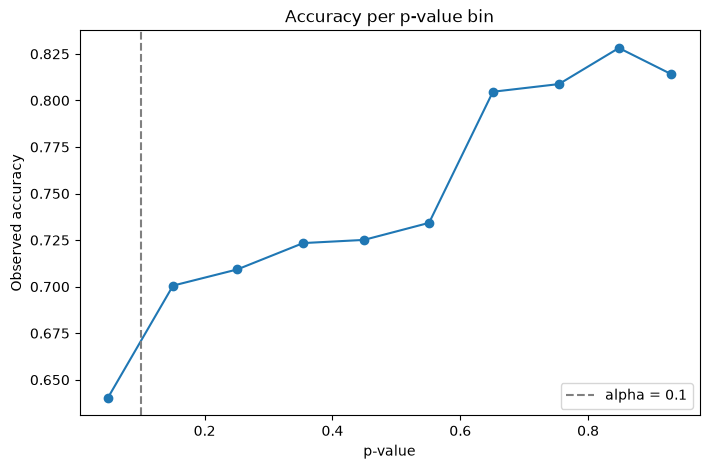

In [203]:
def plot_pvalue_vs_accuracy(results_df, alpha=0.1):
    """Plot the relationship between p-value and accuracy."""
    binned = results_df.assign(correct=results_df["true_class"] == results_df["predicted_class"])
    binned["bin"] = pd.cut(binned["p_value"], bins=np.linspace(0, 1, 11), include_lowest=True)
    per_bin = binned.groupby("bin", observed=True).agg(
        count=("correct", "size"),
        mean_p_value=("p_value", "mean"),
        accuracy=("correct", "mean"),
    )
    display(per_bin)

    plt.figure(figsize=(8, 5))
    plt.plot(per_bin["mean_p_value"], per_bin["accuracy"], marker="o")
    plt.axvline(alpha, color="gray", linestyle="--", label=f"alpha = {alpha}")
    plt.title("Accuracy per p-value bin")
    plt.xlabel("p-value")
    plt.ylabel("Observed accuracy")
    plt.legend()
    plt.show()


plot_pvalue_vs_accuracy(results_df, alpha)

Weighted F1: 		0.7578
Brier: 			0.1435
Combined score: 	0.6490
Mean confidence: 	0.7436
Accuracy: 		0.7615


,count,mean_confidence,accuracy
bin,,,
"(0.1, 0.2]",2,0.174067,0.000000
"(0.2, 0.3]",47,0.270242,0.361702
"(0.3, 0.4]",139,0.357472,0.402878
"(0.4, 0.5]",246,0.453117,0.455285
"(0.5, 0.6]",317,0.548888,0.545741
"(0.6, 0.7]",307,0.651348,0.703583
"(0.7, 0.8]",334,0.754920,0.826347
"(0.8, 0.9]",470,0.853744,0.861702
"(0.9, 1.0]",851,0.958615,0.952996


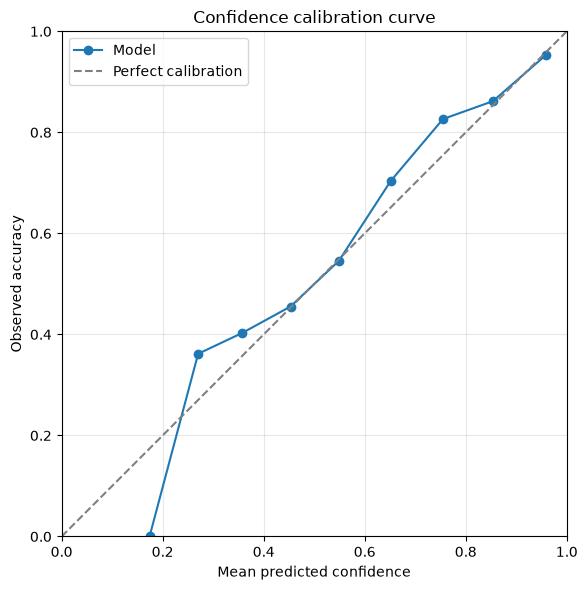

In [204]:
def evaluate_model(proba, y_val):
        
    y_pred = proba.argmax(axis=1)
    confidence = proba.max(axis=1).clip(0, 1)

    correct = (y_pred == y_val).astype(float)
    f1 = f1_score(y_val, y_pred, average="weighted")
    brier = np.mean((confidence - correct) ** 2)

    print(f"Weighted F1: \t\t{f1:.4f}")
    print(f"Brier: \t\t\t{brier:.4f}")
    print(f"Combined score: \t{f1 * (1 - brier):.4f}")
    print(f"Mean confidence: \t{confidence.mean():.4f}")
    print(f"Accuracy: \t\t{correct.mean():.4f}")


    # Compare confidence with observed accuracy within each bin.
    calibration = pd.DataFrame({
        "confidence": confidence,
        "correct": correct,
    })

    # Calculate means per bin. 
    calibration["bin"] = pd.cut(
        calibration["confidence"],
        bins=np.linspace(0, 1, 11),
        include_lowest=True,
    )

    calibration_stats = calibration.groupby("bin", observed=True).agg(
        count=("correct", "size"),
        mean_confidence=("confidence", "mean"),
        accuracy=("correct", "mean"),
    )
    display(calibration_stats)
    fig, ax = plt.subplots(figsize=(8, 6))

    ax.plot(
        calibration_stats["mean_confidence"],
        calibration_stats["accuracy"],
        marker="o",
        label="Model",
    )
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")

    ax.set(
        xlabel="Mean predicted confidence",
        ylabel="Observed accuracy",
        title="Confidence calibration curve",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

evaluate_model(P_val, y_val)

TODO after the run: write what the p-value plot and the calibration curve show here.

## Final Score

Improve the confidence-weighted F1 score to above a threshold which will be above 66%; final threshold will be defined once all submissions have been evaluated (measured on private test dataset; definition of confidence-weighted F1 score provided in notebook)


- Retrain model with best parameters on whole dataset to optimize score on holdout set

For calibration we would need a hold-out set that we can't train on. We skip this, because the confidence is already close to calibrated.

The final model trains on all deduplicated rows, since the validation split already gave us the performance estimate. `predict` returns `(y_pred, y_confidence)`, with the confidence between 0 and 1. `y_pred` contains the encoded labels, and `label_encoder.inverse_transform(y_pred)` gives the industry names.

The feature set comes from `FINAL_FEATURES` in the settings. The private test set comes with financial data, so the final model can use the extra features.

In [205]:
def train_final_model(X, y, fin, groups):
    extra = ExtraFeatures(groups).fit(fin) if groups else None
    F = X if extra is None else np.hstack([X, extra.transform(fin)])

    lr = LogisticRegression(C=3, max_iter=3000).fit(F, y)
    mlps = [make_pipeline(StandardScaler(),
                          MLPClassifier(hidden_layer_sizes=(512,), alpha=1e-2, early_stopping=True, random_state=seed)
                          ).fit(F, y) for seed in range(MLP_SEEDS)]

    mean_embedding = X.mean(axis=0)

    def center(Z):
        Z = Z - mean_embedding
        return Z / np.linalg.norm(Z, axis=1, keepdims=True)

    knn = KNeighborsClassifier(n_neighbors=15, metric="cosine", weights=lambda d: np.exp(-10 * d))
    knn.fit(center(X), y)

    def predict(X_new, fin_new=None):
        F_new = X_new if extra is None else np.hstack([X_new, extra.transform(fin_new)])
        P_mlp = sum(m.predict_proba(F_new) for m in mlps) / len(mlps)
        P = soft_vote(lr.predict_proba(F_new), knn.predict_proba(center(X_new)), P_mlp)
        return P.argmax(axis=1), P.max(axis=1).clip(0, 1)

    return predict


start = time.time()
predict = train_final_model(X, y, fin, FEATURE_SETS[FINAL_FEATURES])
print(f"training time: {(time.time() - start) / 60:.1f} min (limit: 45 min)")

training time: 3.1 min (limit: 45 min)


A quick check of the output format on five training rows. This says nothing about performance, because the model has already seen these rows. On the test set the call is `predict(X_test)`, or `predict(X_test, fin_test)` if the model uses extra features. `fin_test` has to be prepared the same way as `fin`.

In [206]:
y_pred_check, y_confidence_check = predict(X[:5], fin.iloc[:5])
assert np.all((y_confidence_check >= 0) & (y_confidence_check <= 1))
print(label_encoder.inverse_transform(y_pred_check))
print(y_confidence_check.round(3))

['Banks' 'Materials' 'Commercial & Professional Services' 'Insurance'
 'Capital Goods']
[0.968 0.862 0.479 0.995 0.889]
